<a href="https://colab.research.google.com/github/yuukienomoto/report_-syobon_n/blob/main/%E3%82%A6%E3%83%AB%E3%83%88%E3%83%A9%E7%AB%8B%E7%9B%B4_%E6%B1%8E%E5%8C%96%E6%80%A7%E8%83%BDipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## ■ 1. 席順特定・試合データ集計・強弱ターゲット切り出し処理

### 【処理の目的】
膨大な牌譜ログ（XMLデータ）から必要な情報だけを極限まで絞り込んで読み込み、メモリ消費を抑えながら、機械学習モデルの予測対象となる「強（ラベル1）」と「弱（ラベル0）」の試合データを抽出・作成します。

### 【主な処理フロー】
1. **メモリを抑えたデータロード**: XMLから解析に必要な最小限の属性（席順特定用のプレイヤー名、アガリ・放銃計算用のID、段位）のみを抽出して読み込みます。
2. **プレイヤー席順の特定（shobon_map）**: 全対局ログの `UN` タグから「しょぼんｎ」というプレイヤー名をデコードし、各試合における席順（0〜3）を正確に特定します。
3. **試合単位のスタッツ集計**: 局単位の生ログを試合単位（`file_id`）にグループ化し、総局数・アガリ回数・放銃回数、およびその試合時点での段位を集計します。
4. **データの切り出し（ノイズ除去）**:
   * アカウント初期の慣らし運転期間である「最初の1,500試合」をカット。
   * 実力が最も安定している時期「段位18以上（強：1）」と、スランプに陥っている時期「段位16以下（弱：0）」にラベル分け。
   * どちらとも言えない移行期の「段位17」の試合をノイズとして完全に除外。

### 【最終出力】
* `model_target_df` (学習用ターゲットデータ)
  * **弱 (0 / 段位16以下)**: 4,735試合
  * **強 (1 / 段位18以上)**: 1,280試合
  * **合計**: 6,015試合

In [17]:
# ==============================================================================
# 1. ライブラリのインポートと解析関数の定義
# ==============================================================================
import xml.etree.ElementTree as ET
import pandas as pd
import numpy as np
import zipfile
import gzip
import gc
import urllib.parse
import random

def verify_and_create_dataset(zip_path):
    all_rows = []
    print("1. 全ファイルの解析を開始します（生データのメモリ効率化ロード）...")

    with zipfile.ZipFile(zip_path, 'r') as z:
        file_list = [f for f in z.namelist() if f.endswith('.mjlog')]

        for file_name in file_list:
            with z.open(file_name) as f:
                content = gzip.decompress(f.read())
                root = ET.fromstring(content)

                for child in root:
                    # **child.attrib で展開していた過去のロジックを忠実に再現
                    record = {**child.attrib, 'tag_type': child.tag, 'file_id': file_name}
                    all_rows.append(record)

    df = pd.DataFrame(all_rows)
    print(f"成功: {df['file_id'].nunique()} 個の全ファイルからデータを正常に取得しました。")
    print(f"総イベント数: {len(df)}")
    return df

# ==============================================================================
# 2. データのロード
# ==============================================================================
zip_path = '/content/drive/MyDrive/卒論/mjlog_pf4-20_n30.zip'
df = verify_and_create_dataset(zip_path)
gc.collect()

# ==============================================================================
# 3. 席順特定（shobon_map の作成）
# ==============================================================================
print("\n2. 席順特定（shobon_mapの作成）を実行中...")
un_df = df[df['tag_type'] == 'UN'].copy()

for i in range(4):
    col = f'n{i}'
    un_df[f'is_shobon_{i}'] = un_df[col].apply(lambda x: "しょぼんｎ" in urllib.parse.unquote(str(x)))

un_df['shobon_seat'] = -1
for i in range(4):
    un_df.loc[un_df[f'is_shobon_{i}'], 'shobon_seat'] = i

shobon_map = un_df[un_df['shobon_seat'] != -1].set_index('file_id')['shobon_seat'].to_dict()
print(f"   特定完了: {len(shobon_map)} ファイル分の席順を確定しました")

# メモリ解放
del un_df
gc.collect()

# ==============================================================================
# 4. 正確な段位の抽出（dan_map の作成 ➔ メインDFへの適用）
# ==============================================================================
print("\n3. 段位抽出（dan_mapの作成）を実行中...")
dan_map = {}
un_df = df[df['tag_type'] == 'UN'].copy()

for _, row in un_df.iterrows():
    file_id = row['file_id']
    if file_id in dan_map:
        continue

    if file_id in shobon_map:
        seat = shobon_map[file_id]
        dan_raw = str(row.get('dan', ''))
        dan_list = dan_raw.split(',')

        if seat < len(dan_list) and dan_list[seat] != '':
            dan_map[file_id] = int(dan_list[seat])

# メイン df に適用
df['shobon_dan'] = df['file_id'].map(dan_map)
print(f"   段位取得成功: {len(dan_map)} 件の対局の段位を取得しました。")

# メモリ解放
del un_df
gc.collect()

# ==============================================================================
# 5. 試合単位での結果スタッツの集計
# ==============================================================================
print("\n4. 試合単位での結果スタッツの集計中...")

# who, fromWho を数値に変換
df['who_num'] = pd.to_numeric(df['who'], errors='coerce')
df['fromWho_num'] = pd.to_numeric(df['fromWho'], errors='coerce')
df['shobon_seat_num'] = pd.to_numeric(df['file_id'].map(shobon_map), errors='coerce')

df['is_agari_raw'] = np.where((df['tag_type'] == 'AGARI') & (df['who_num'] == df['shobon_seat_num']), 1, 0)
df['is_hoju_raw'] = np.where(
    (df['tag_type'] == 'AGARI') &
    (df['fromWho_num'] == df['shobon_seat_num']) &
    (df['who_num'] != df['shobon_seat_num']),
    1, 0
)
df['is_init_raw'] = np.where(df['tag_type'] == 'INIT', 1, 0)

# 試合単位への集計
clean_game_df = df.groupby('file_id').agg(
    total_rounds=('is_init_raw', 'sum'),
    total_agari=('is_agari_raw', 'sum'),
    total_hoju=('is_hoju_raw', 'sum'),
    shobon_dan=('shobon_dan', 'max') # 確実に段位の数値を残す
).reset_index()

# 巨大な生データフレーム(df)をここで完全に消し去り、メモリをガッツリ確保する
del df
gc.collect()

# ==============================================================================
# 6. 時系列順ソート ➔ 初期1500試合カット ➔ ラベル切り分け
# ==============================================================================
# 時系列順（file_id 順）にソート
clean_game_df = clean_game_df.sort_values('file_id').reset_index(drop=True)

# 初期1500試合をカット
clean_game_df = clean_game_df.iloc[1500:].reset_index(drop=True)
print(f"   初期1,500試合除外後のデータ件数: {len(clean_game_df)} 試合")

print("\n5. 段位による強弱ラベル付与（18以上 vs 16以下）と中間層（17）の除外を実行中...")
conditions = [
    (clean_game_df['shobon_dan'] >= 18.0), # 強 (1)
    (clean_game_df['shobon_dan'] <= 16.0)  # 弱 (0)
]
choices = [1, 0]

clean_game_df['target_label'] = np.select(conditions, choices, default=np.nan)

# NaN（段位17や、段位情報が万が一取れなかった試合）を除外
model_target_df = clean_game_df.dropna(subset=['target_label']).copy()
model_target_df['target_label'] = model_target_df['target_label'].astype(int)

# 中間生成された不要なデータフレームを削除
del clean_game_df
gc.collect()

print("\n==============================================")
print("🎉 【処理完了】ターゲットデータが完成しました")
print("==============================================")
print(model_target_df['target_label'].value_counts())
print(f"総学習用データ件数: {len(model_target_df)} 試合 (強: 1280 / 弱: 4735)")

1. 全ファイルの解析を開始します（生データのメモリ効率化ロード）...
成功: 11573 個の全ファイルからデータを正常に取得しました。
総イベント数: 12365541

2. 席順特定（shobon_mapの作成）を実行中...
   特定完了: 11573 ファイル分の席順を確定しました

3. 段位抽出（dan_mapの作成）を実行中...
   段位取得成功: 11573 件の対局の段位を取得しました。

4. 試合単位での結果スタッツの集計中...
   初期1,500試合除外後のデータ件数: 10073 試合

5. 段位による強弱ラベル付与（18以上 vs 16以下）と中間層（17）の除外を実行中...

🎉 【処理完了】ターゲットデータが完成しました
target_label
0    4735
1    1280
Name: count, dtype: int64
総学習用データ件数: 6015 試合 (強: 1280 / 弱: 4735)


## ■ 6. 【ミクロ戦術の核心】18大ミクロ戦術特徴量の一括抽出処理

### 【処理の目的】
1試合のぼんやりとした平均値（マクロデータ）を捨て、「他家リーチのプレッシャー下」という攻防の葛藤が発生するミクロな局面にズームインします。
「局の進行度（序・中・終盤）」や「点数状況（トップ目・ラス目）」といった文脈（コンテキスト）におけるプレイヤーの実際の選択を数値化し、強者と弱者の「決断の構造の違い」を18次元の特徴量として描き出します。

# ■ 17大ミクロ戦術特徴量 定義一覧

他家からリーチが入っている、あるいは流局間際であるといった**「攻防の葛藤が発生する局所的な場面」**における、一打一打の決断を数値化した17個の特徴量です。

---

## 1. 守備のミクロ（リーチ直後の一発目）
他家リーチが入った直後の最初の一打は、最も守備技術とプレッシャー耐性が試される瞬間です。

| 特徴量名 | 定義・数理的意味 | 麻雀における戦術的解釈 |
| :--- | :--- | :--- |
| **`first_discard_safe_rate`** | 他家リーチが入った最初の一打（初打）で、**現物（安全牌）を正確に切ってオリに回れた割合** | プレッシャーを受けた瞬間、即座に安全第一の守備ルートを選択できているか（日和の指標） |
| **`first_discard_raw_unsafe_rate`** | 他家リーチの最初の一打で、**現物でもスジでもない「無筋（危険牌）」を押した割合** | 相手のリーチに対して安易に引き下がらず、自分の手牌の価値を優先して真っ向勝負を選んだ割合 |

---

## 2. 巡目別の押し引き（他家リーチ中のノーテン時）
自分がテンパイしていない（アガれない）状況で、他家リーチに対して危険牌を押し切ってしまった割合を、巡目（局の深さ）ごとに分解したものです。

| 特徴量名 | 定義・数理的意味 | 麻雀における戦術的解釈 |
| :--- | :--- | :--- |
| **`early_noten_push_rate`** | **【序盤：1〜6巡目】** 他家リーチ中、ノーテンから危険牌を押した割合 | 自分の手がまだ育つ余地がある早い段階で、諦めずに手広く受け流しながら粘れているか |
| **`mid_noten_push_rate`** | **【中盤：7〜12巡目】** 他家リーチ中、ノーテンから危険牌を押した割合 | 相手の待ちが絞れ始める中盤で、引き際を間違えず、適切なタイミングで守備シフトできているか |
| **`late_noten_push_rate`** | **【終盤：13巡目以降】** 他家リーチ中、ノーテンから危険牌を押した割合 | 流局間際の極限状態で、耐えきれずにド無筋を叩き出して放銃する自滅（プレッシャー負け）を防げているか |

---

## 3. 点数状況・プレッシャー別の押し引き（他家リーチ中）
現在の点数と順位の状況（トップ・平場・ラス）によって、押し引きの論理的な判断基準は大きく変化します。

| 特徴量名 | 定義・数理的意味 | 麻雀における戦術的解釈 |
| :--- | :--- | :--- |
| **`top_conservative_push_rate`** | **自分がトップ目（1位）の時**、他家リーチに対して危険牌を押した割合 | リードを守りきるために、自分のテンパイを崩してでも100%ベタオリに徹する冷静さがあるか（低いほど強い） |
| **`flat_situation_push_rate`** | **平場（2位・3位の競り合いの時）**、他家リーチに対して危険牌を押した割合 | 標準的な状況下において、リスクとリターンを天秤にかける基本的な押し引きの精密さ |
| **`las_desperate_push_rate`** | **自分がラス目（4位）の時**、他家リーチに対して危険牌を押した割合 | 「放銃のリスクを負ってでもアガらなければラス」という窮地で、腹を括って死に物狂いで押し切れているか |

---

## 4. 攻撃のミクロ（リーチ判断・打点意識）
自分のリーチ判断が、合理的かつ勝算のある質を伴っているかを捉えます。

| 特徴量名 | 定義・数理的意味 | 麻雀における戦術的解釈 |
| :--- | :--- | :--- |
| **`riichi_dora_mean`** | 自分がリーチをかけた際、**手牌に含まれていた平均ドラ数** | 安易なリーのみ等の安手を避け、十分に勝負に見合う高打点（ドラ持ち）のリーチを狙えているか |
| **`chasing_riichi_good_shape_rate`**| **追いかけリーチ（他家リーチがある状況）を打った際**、待ちが両面以上の良形だった割合 | 他家に先制されている不利な状況で、勝率の高い「良形待ち」を冷静に厳選できているか |
| **`chasing_riichi_low_value_rate`** | **追いかけリーチを打った際**、ドラが0枚などの「安手」だった割合 | 焦りから、勝算もリターンも薄い無謀な追いかけリーチを打って他家に放銃カウンターを喰らっていないか |

---

## 5. 仕掛けのミクロ（ポン・チーのスピード・質）
鳴き仕掛けを入れるタイミングと、その手の「質（打点）」を監視します。

| 特徴量名 | 定義・数理的意味 | 麻雀における戦術的解釈 |
| :--- | :--- | :--- |
| **`early_meld_ratio`** | **【序盤：1〜6巡目】** にポンやチーなどの仕掛けを入れた局の割合 | 序盤の早い段階から仕掛けを入れて、ゲームの主導権とスピードを握りに行けているか |
| **`late_meld_ratio`** | **【終盤：13巡目以降】** に初めて仕掛けを入れた局の割合 | 流局間際に、ノーテン罰符を嫌って形式テンパイを貪欲に拾いに行く、しぶとい鳴きができているか |
| **`meld_dora_ratio`** | 自分が仕掛けを入れた局のうち、**手牌にドラが1枚以上あった割合** | 守備力を失う「鳴き」を行う際に、役なしドラなしの安い仕掛け（自滅パターン）を避け、打点を伴っているか |

---

## 6. ベタオリの技術 ＆ 局終盤のねばり
他家の攻勢をいかにいなし、流局時の罰符（ノーテン罰符）をコントロールできているかというミクロな守備技術です。

| 特徴量名 | 定義・数理的意味 | 麻雀における戦術的解釈 |
| :--- | :--- | :--- |
| **`raw_unsafe_discard_rate`** | 他家リーチに対し、安全牌以外の牌（無筋）を切ってプッシュした全体の割合 | 試合全体を通して、他家リーチに対して引かずにどれだけ押し返しの姿勢を見せているか |
| **`ryuukyoku_tenpai_rate`** | 流局時（RYUUKYOKU）に、自分がテンパイを維持できていた割合 | 局の最後まで諦めず、安全を確保しながら形式テンパイなどを取り切る執念（粘り強さ） |
| **`ryuukyoku_noten_safe_rate`** | 流局時にノーテン（開示なし）で終わった局において、**他家に放銃せずに安全にオリきれた割合** | 自分のアガリを完全に諦めてから、流局まで100%安全にオリきるベタオリの技術的な精度 |

In [18]:
import xml.etree.ElementTree as ET
import pandas as pd
import numpy as np
import zipfile
import gzip
import gc

def extract_micro_tactical_features(zip_path, target_df, shobon_map):
    print("🚀 6,015試合の牌譜から18のミクロ戦術特徴量を一括抽出中...")
    target_files = set(target_df['file_id'].unique())
    features_list = []

    draw_prefixes = ('T', 'U', 'V', 'W')
    discard_prefixes = ('D', 'E', 'F', 'G')

    with zipfile.ZipFile(zip_path, 'r') as z:
        for idx, file_name in enumerate(target_files):
            if idx > 0 and idx % 500 == 0:
                print(f"   進捗: {idx} / {len(target_files)} 試合完了...")

            with z.open(file_name) as f:
                content = gzip.decompress(f.read())
                root = ET.fromstring(content)

                my_seat = shobon_map.get(file_name, -1)
                if my_seat == -1:
                    continue

                # --- 試合ごとのミクロ集計カウンター ---
                # 1. 守備のミクロ（一発目）
                first_discard_opp_reach_count = 0
                first_discard_raw_unsafe_count = 0
                first_discard_safe_count = 0

                # 2. 巡目別の押し引き（他家リーチ中、かつ自分がノーテン）
                opp_reach_noten_turns_early_count = 0
                opp_reach_noten_push_early_count = 0

                opp_reach_noten_turns_mid_count = 0
                opp_reach_noten_push_mid_count = 0

                opp_reach_noten_turns_late_count = 0
                opp_reach_noten_push_late_count = 0

                # 3. 点数状況別の押し引き（他家リーチ中）
                opp_reach_turns_as_last = 0
                opp_reach_push_as_last = 0

                opp_reach_turns_as_top = 0
                opp_reach_push_as_top = 0

                opp_reach_turns_as_flat = 0
                opp_reach_push_as_flat = 0

                # 4. 攻撃のミクロ（リーチ時）
                my_reach_count = 0
                my_reach_dora_sum = 0

                # 追っかけリーチ関連
                chasing_reach_count = 0
                chasing_reach_good_shape_count = 0  # 簡易判定
                chasing_reach_low_value_count = 0   # 簡易判定

                # 5. 仕掛けのミクロ（ポン・チー）
                total_rounds = 0
                rounds_with_early_meld = 0
                rounds_with_late_meld = 0
                rounds_with_meld_dora = 0

                # 6. ベタオリの技術・局終盤
                opp_reach_turns_total = 0
                opp_reach_suji_push_count = 0
                opp_reach_raw_unsafe_push_count = 0

                total_ryuukyoku_rounds = 0
                ryuukyoku_tenpai_count = 0
                ryuukyoku_noten_safe_count = 0

                current_round = None

                for child in root:
                    tag = child.tag
                    attrib = child.attrib

                    if tag == 'INIT':
                        total_rounds += 1
                        my_hai_attr = attrib.get(f'hai{my_seat}', '')
                        my_hand = [int(x) for x in my_hai_attr.split(',')] if my_hai_attr else []

                        seed = attrib.get('seed', '')
                        dora_indicators = []
                        if seed:
                            seed_list = seed.split(',')
                            if len(seed_list) > 5:
                                dora_indicators.append(int(seed_list[5]))

                        # 局開始時の点数・順位の把握
                        tens_str = attrib.get('ten', '')
                        my_rank = 1  # デフォルトトップ
                        my_score = 25000
                        if tens_str:
                            tens = [int(t) * 100 for t in tens_str.split(',')]
                            if my_seat < len(tens):
                                my_score = tens[my_seat]
                                # 順位算出
                                my_rank = 1 + sum(1 for other_score in tens if other_score > my_score)

                        discard_history = {0: [], 1: [], 2: [], 3: []}
                        active_reach_players = set()
                        shobon_draw_count = 0
                        has_melded_this_round = False
                        shobon_discarded_after_reach = False
                        reacher_seat = -1
                        is_menzen = True

                        my_reach_processed_this_round = False
                        current_round = True
                        continue

                    if not current_round:
                        continue

                    if tag == 'DORA':
                        dora_indicators.append(int(attrib.get('hai', -1)))
                        continue

                    # 他家のリーチ検知
                    if tag == 'REACH':
                        p_reach = int(attrib.get('who', -1))
                        step = str(attrib.get('step', ''))

                        if p_reach != my_seat and step == '1':
                            active_reach_players.add(p_reach)
                            reacher_seat = p_reach
                            shobon_discarded_after_reach = False
                            first_discard_opp_reach_count += 1

                        elif p_reach == my_seat and not my_reach_processed_this_round:
                            my_reach_processed_this_round = True
                            my_reach_count += 1

                            # ドラ数簡易算出
                            dora_tiles = []
                            for ind in dora_indicators:
                                ind_type = ind // 4
                                if ind_type < 27:
                                    dora_tile = ind_type + 1 if ind_type % 9 != 8 else ind_type - 8
                                else:
                                    if ind_type < 31:
                                        dora_tile = ind_type + 1 if ind_type < 30 else 27
                                    else:
                                        dora_tile = ind_type + 1 if ind_type < 33 else 31
                                dora_tiles.append(dora_tile)
                            my_dora_count = sum(1 for tile in my_hand if (tile // 4) in dora_tiles)
                            my_reach_dora_sum += my_dora_count

                            # 追いかけリーチのミクロ判定
                            if len(active_reach_players) > 0:
                                chasing_reach_count += 1
                                # 簡易良形判定（ツモ牌を含む手牌14枚に重複ペアが少ない＝多面待ちが残りやすい）
                                if len(set([t // 4 for t in my_hand])) >= 10:
                                    chasing_reach_good_shape_count += 1
                                # 簡易低打点判定（ドラが0枚）
                                if my_dora_count == 0:
                                    chasing_reach_low_value_count += 1

                    # 仕掛け（ポン・チー）の検知
                    if tag == 'N':
                        who_meld = int(attrib.get('who', -1))
                        if who_meld == my_seat:
                            is_menzen = False
                            if not has_melded_this_round:
                                has_melded_this_round = True
                                # 序盤（1〜6巡目）の仕掛け
                                if shobon_draw_count <= 6:
                                    rounds_with_early_meld += 1
                                # 終盤（13巡目以降）の仕掛け
                                elif shobon_draw_count >= 13:
                                    rounds_with_late_meld += 1

                                # ドラ持ち仕掛け
                                dora_tiles = []
                                for ind in dora_indicators:
                                    ind_type = ind // 4
                                    if ind_type < 27:
                                        dora_tile = ind_type + 1 if ind_type % 9 != 8 else ind_type - 8
                                    else:
                                        if ind_type < 31:
                                            dora_tile = ind_type + 1 if ind_type < 30 else 27
                                        else:
                                            dora_tile = ind_type + 1 if ind_type < 33 else 31
                                    dora_tiles.append(dora_tile)
                                if any((tile // 4) in dora_tiles for tile in my_hand):
                                    rounds_with_meld_dora += 1

                    # 自分がツモ
                    for seat, prefix in enumerate(draw_prefixes):
                        if tag.startswith(prefix) and tag[1:].isdigit():
                            tile_drawn = int(tag[1:])
                            if seat == my_seat:
                                my_hand.append(tile_drawn)
                                shobon_draw_count += 1

                    # 誰かが捨てる
                    for seat, prefix in enumerate(discard_prefixes):
                        if tag.startswith(prefix) and tag[1:].isdigit():
                            tile_discarded = int(tag[1:])
                            discard_history[seat].append(tile_discarded)

                            if seat == my_seat:
                                if tile_discarded in my_hand:
                                    my_hand.remove(tile_discarded)

                                # 他家リーチ中の打牌判定
                                if active_reach_players:
                                    opp_reach_turns_total += 1
                                    reacher_discards = set(discard_history[reacher_seat])
                                    is_safe = (tile_discarded // 4) in [t // 4 for t in reacher_discards]

                                    # ①一発目（初打）のミクロ判断
                                    if not shobon_discarded_after_reach:
                                        if is_safe:
                                            first_discard_safe_count += 1
                                        else:
                                            # 無筋プッシュ（リーチ宣言者の河に同じ牌がない、かつスジでもない簡易判定）
                                            # スジ判定用
                                            is_suji = False
                                            tile_type = tile_discarded // 4
                                            if tile_type < 27:
                                                num = tile_type % 9
                                                # スジ：1が安全なら4、4が安全なら1と7、9が安全なら6など
                                                # ここでは簡易的に安全牌リストに基づく無筋を検出
                                                pass
                                            first_discard_raw_unsafe_count += 1
                                        shobon_discarded_after_reach = True

                                    # 簡易ノーテン判定 (鳴いておらず、かつリーチもしていない場合をノーテンと仮定)
                                    is_noten = is_menzen and (not my_reach_processed_this_round)

                                    # ②巡目別のノーテン押し引き
                                    if is_noten:
                                        if shobon_draw_count <= 6:
                                            opp_reach_noten_turns_early_count += 1
                                            if not is_safe:
                                                opp_reach_noten_push_early_count += 1
                                        elif shobon_draw_count <= 12:
                                            opp_reach_noten_turns_mid_count += 1
                                            if not is_safe:
                                                opp_reach_noten_push_mid_count += 1
                                        else:
                                            opp_reach_noten_turns_late_count += 1
                                            if not is_safe:
                                                opp_reach_noten_push_late_count += 1

                                    # ③点数状況別の押し引き
                                    if my_rank == 4: # ラス目
                                        opp_reach_turns_as_last += 1
                                        if not is_safe:
                                            opp_reach_push_as_last += 1
                                    elif my_rank == 1: # トップ目
                                        opp_reach_turns_as_top += 1
                                        if not is_safe:
                                            opp_reach_push_as_top += 1
                                    else: # 平場（2位・3位）
                                        opp_reach_turns_as_flat += 1
                                        if not is_safe:
                                            opp_reach_push_as_flat += 1

                                    # ④ベタオリ技術（スジ押し・無筋プッシュ）
                                    if not is_safe:
                                        opp_reach_raw_unsafe_push_count += 1

                    # 局の結末が流局（RYUUKYOKU）の場合
                    if tag == 'RYUUKYOKU':
                        total_ryuukyoku_rounds += 1
                        # 自分がテンパイ流局したか（手牌開示属性から判定）
                        # 天鳳ではテンパイ者は手牌を開示するため、hai属性がログに記録される
                        my_meld_attr = child.attrib.get(f'hai{my_seat}', '')
                        if my_meld_attr:
                            ryuukyoku_tenpai_count += 1
                        else:
                            # ノーテンで放銃せずにオリきれた局数
                            # (誰かに放銃（AGARI）されずに流局を迎えられたため、ノーテンなら安全にオリきったとみなす)
                            ryuukyoku_noten_safe_count += 1

                # 1試合の解析完了。18大特徴量の算出
                features_list.append({
                    'file_id': file_name,
                    # 1. 守備のミクロ
                    'first_discard_raw_unsafe_rate': first_discard_raw_unsafe_count / first_discard_opp_reach_count if first_discard_opp_reach_count > 0 else np.nan,
                    'first_discard_safe_rate': first_discard_safe_count / first_discard_opp_reach_count if first_discard_opp_reach_count > 0 else np.nan,

                    # 2. 巡目別の押し引き
                    'early_noten_push_rate': opp_reach_noten_push_early_count / opp_reach_noten_turns_early_count if opp_reach_noten_turns_early_count > 0 else np.nan,
                    'mid_noten_push_rate': opp_reach_noten_push_mid_count / opp_reach_noten_turns_mid_count if opp_reach_noten_turns_mid_count > 0 else np.nan,
                    'late_noten_push_rate': opp_reach_noten_push_late_count / opp_reach_noten_turns_late_count if opp_reach_noten_turns_late_count > 0 else np.nan,

                    # 3. 点数状況別の押し引き
                    'las_desperate_push_rate': opp_reach_push_as_last / opp_reach_turns_as_last if opp_reach_turns_as_last > 0 else np.nan,
                    'top_conservative_push_rate': opp_reach_push_as_top / opp_reach_turns_as_top if opp_reach_turns_as_top > 0 else np.nan,
                    'flat_situation_push_rate': opp_reach_push_as_flat / opp_reach_turns_as_flat if opp_reach_turns_as_flat > 0 else np.nan,

                   # 4. 攻撃のミクロ
                        'riichi_dora_mean': my_reach_dora_sum / my_reach_count if my_reach_count > 0 else np.nan,
                        'chasing_riichi_good_shape_rate': chasing_reach_good_shape_count / chasing_reach_count if chasing_reach_count > 0 else np.nan,
                        'chasing_riichi_low_value_rate': chasing_reach_low_value_count / chasing_reach_count if chasing_reach_count > 0 else np.nan,

                        # ★★★ ここを追加（真の追っかけリーチ率） ★★★
                        'chasing_riichi_rate': chasing_reach_count / first_discard_opp_reach_count if first_discard_opp_reach_count > 0 else np.nan,
                    # 5. 仕掛けのミクロ
                    'early_meld_ratio': rounds_with_early_meld / total_rounds if total_rounds > 0 else 0.0,
                    'late_meld_ratio': rounds_with_late_meld / total_rounds if total_rounds > 0 else 0.0,
                    'meld_dora_ratio': rounds_with_meld_dora / total_rounds if total_rounds > 0 else 0.0,

                    # 6. ベタオリの技術・局終盤
                    'raw_unsafe_discard_rate': opp_reach_raw_unsafe_push_count / opp_reach_turns_total if opp_reach_turns_total > 0 else np.nan,
                    'ryuukyoku_tenpai_rate': ryuukyoku_tenpai_count / total_ryuukyoku_rounds if total_ryuukyoku_rounds > 0 else np.nan,
                    'ryuukyoku_noten_safe_rate': ryuukyoku_noten_safe_count / total_ryuukyoku_rounds if total_ryuukyoku_rounds > 0 else np.nan
                })

    return pd.DataFrame(features_list)

# 特徴量抽出の実行（6,015試合から18のミクロ特徴量を抽出）
micro_features_df = extract_micro_tactical_features(zip_path, model_target_df, shobon_map)

# 特徴量結合と欠損値補完（1試合の局所的な事象のため、発生しなかった試合は全体平均で埋めます）
micro_dataset_df = pd.merge(model_target_df, micro_features_df, on='file_id', how='inner')
micro_dataset_df.fillna(micro_dataset_df.mean(numeric_only=True), inplace=True)

print("\n==============================================")
print("🎉 【ミクロ特徴量・構築完了】18次元の戦術データが整いました")
print("==============================================")
print(f"データフレームの形状: {micro_dataset_df.shape} (試合数, 特徴量数)")
print(micro_dataset_df.head())

🚀 6,015試合の牌譜から18のミクロ戦術特徴量を一括抽出中...
   進捗: 500 / 6015 試合完了...
   進捗: 1000 / 6015 試合完了...
   進捗: 1500 / 6015 試合完了...
   進捗: 2000 / 6015 試合完了...
   進捗: 2500 / 6015 試合完了...
   進捗: 3000 / 6015 試合完了...
   進捗: 3500 / 6015 試合完了...
   進捗: 4000 / 6015 試合完了...
   進捗: 4500 / 6015 試合完了...
   進捗: 5000 / 6015 試合完了...
   進捗: 5500 / 6015 試合完了...
   進捗: 6000 / 6015 試合完了...

🎉 【ミクロ特徴量・構築完了】18次元の戦術データが整いました
データフレームの形状: (6015, 24) (試合数, 特徴量数)
                                             file_id  total_rounds  \
0  mjlog_pf4-20_n30/2012062303gm-0029-0000-bb2d01...            11   
1  mjlog_pf4-20_n30/2012062304gm-0029-0000-dff1fa...            11   
2  mjlog_pf4-20_n30/2012062311gm-0029-0000-f8bbd4...            13   
3  mjlog_pf4-20_n30/2012062312gm-0029-0000-006c5e...            12   
4  mjlog_pf4-20_n30/2012062316gm-0029-0000-c3810c...             9   

   total_agari  total_hoju  shobon_dan  target_label  \
0            2           1          14             0   
1            0           5          14   

#追加

##クロス特徴量の定義
# ■ 拡張クロス戦術特徴量（交互作用）定義一覧

独立した戦術要素（巡目・点数状況・手の価値など）を掛け合わせ、「特定の戦況下において下された意思決定の妥当性や質」を多角的に捉える5つの新特徴量です。

---

## 7. 状況適応型の意思決定（点数状況 × 巡目・仕掛け）

現在の順位・点差とゲームの進行度（巡目）の組み合わせによって、押し引きや仕掛けの正着手は正反対に変化します。

| 特徴量名 | 定義・数理的意味 | 麻雀における戦術的解釈 |
| --- | --- | --- |
| **`top_late_noten_push_rate`** | **トップ目の押し率 × 終盤ノーテン押し率**<br>

<br>（`top_conservative_push_rate` × `late_noten_push_rate`） | 局の終盤、リードを守るべきトップ目であるにもかかわらずノーテンから危険牌を押してしまう「最悪の自滅行動」を検知する指標 |
| **`las_early_meld_rate`** | **ラス目の押し率 × 序盤仕掛け率**<br>

<br>（`las_desperate_push_rate` × `early_meld_ratio`） | 4位（ラス目）の劣勢時において、早い巡目から積極的に手を動かしてゲームの主導権と加点チャンスを貪欲に奪いに行けているか |

---

## 8. 打点と速度のバランス（仕掛け・リーチの純度）

単なる攻めの頻度ではなく、「打点が伴っているか」「勝算に見合っているか」という勝負手の質を評価します。

| 特徴量名 | 定義・数理的意味 | 麻雀における戦術的解釈 |
| --- | --- | --- |
| **`early_meld_with_dora_rate`** | **序盤仕掛け率 × ドラ所持率**<br>

<br>（`early_meld_ratio` × `meld_dora_ratio`） | 序盤（1〜6巡目）から鳴く際に、ドラを確保して打点を担保できている割合（安手での守備力放棄を防ぎ、効率的な加点を狙えているか） |
| **`chasing_riichi_quality_ratio`** | **追っかけ良形率 / 追っかけ安手率**<br>

<br>（`chasing_riichi_good_shape_rate` / `chasing_riichi_low_value_rate`） | 他家リーチに押し返す際、「勝率の高い良形待ち」を選び、「リターンの薄い安手」をどれだけ避けているかを表す追っかけリーチの選別精度 |

---

## 9. 競り合い時の守備徹底度（平場 × 初打守備）

点数が横並びの標準的な局面における、リーチ一発目のケア精度を測定します。

| 特徴量名 | 定義・数理的意味 | 麻雀における戦術的解釈 |
| --- | --- | --- |
| **`flat_first_discard_safe_rate`** | **初打現物オリ率 × 平場非プッシュ率**<br>

<br>（`first_discard_safe_rate` × `(1 - flat_situation_push_rate)`） | 2位・3位の競り合い状況において、無理な全ツッパを避けつつ他家リーチの一発目に確実に安全牌を切れているかという守備の冷静さ |

In [19]:
# ==============================================================================
# 🛠️ クロス特徴量（交互作用特徴量）の生成（自動列取得版）
# ==============================================================================
# 1. 抽出関数（micro_features_df）から作られた特徴量カラムを自動取得
exclude_cols = ['file_id', 'target_label', 'dan', 'rate', 'game_date']
micro_features = [c for c in micro_features_df.columns if c not in exclude_cols]

# 2. 状況 × 巡目：トップ目の終盤ノーテンプッシュ
micro_dataset_df['top_late_noten_push_rate'] = (
    micro_dataset_df['top_conservative_push_rate'] * micro_dataset_df['late_noten_push_rate']
)

# 3. 状況 × 仕掛け：ラス目での序盤仕掛け
micro_dataset_df['las_early_meld_rate'] = (
    micro_dataset_df['las_desperate_push_rate'] * micro_dataset_df['early_meld_ratio']
)

# 4. 仕掛け巡目 × 打点：序盤の質の高い仕掛け
micro_dataset_df['early_meld_with_dora_rate'] = (
    micro_dataset_df['early_meld_ratio'] * micro_dataset_df['meld_dora_ratio']
)

# 5. 追っかけリーチの精度：差分（良形率 - 安手率）
micro_dataset_df['chasing_riichi_quality_diff'] = (
    micro_dataset_df['chasing_riichi_good_shape_rate'] - micro_dataset_df['chasing_riichi_low_value_rate']
)

# 6. 防守の徹底度：平場におけるリーチ一発目の現物オリ率
micro_dataset_df['flat_first_discard_safe_rate'] = (
    micro_dataset_df['first_discard_safe_rate'] * (1.0 - micro_dataset_df['flat_situation_push_rate'])
)

# 7. 追加特徴量リスト
new_cross_features = [
    'top_late_noten_push_rate',
    'las_early_meld_rate',
    'early_meld_with_dora_rate',
    'chasing_riichi_quality_diff',
    'flat_first_discard_safe_rate'
]

# 重複を防いで全特徴量リストを作成（chasing_riichi_rate は micro_features に自動で入っています）
all_features_v2 = list(dict.fromkeys(micro_features + new_cross_features))

print(f"■ 特徴量数: 合計 {len(all_features_v2)} 次元")

■ 特徴量数: 合計 23 次元


## LightGBMによるモデル構築と特徴量重要度の可視化（10試合平滑化）

#Optunaのインストール

In [20]:
!pip install optuna

In [21]:
import optuna
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np

# Optunaのログをすっきりさせる
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'class_weight': 'balanced',
        'random_state': 42,
        'n_estimators': 200,
        # 安定した範囲に絞ったハイパーパラメータの探索
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 63),
        'max_depth': trial.suggest_int('max_depth', 3, 7),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 1.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 1.0, log=True),
        'verbosity': -1
    }

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    auc_scores = []

    for train_idx, val_idx in skf.split(X_rolled, y_rolled):
        X_train, y_train = X_rolled.iloc[train_idx], y_rolled.iloc[train_idx]
        X_val, y_val = X_rolled.iloc[val_idx], y_rolled.iloc[val_idx]

        model = lgb.LGBMClassifier(**params)
        model.fit(
            X_train, y_train,
            eval_set=[(X_val, y_val)],
            callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=False)]
        )

        preds = model.predict_proba(X_val)[:, 1]
        score = roc_auc_score(y_val, preds)
        auc_scores.append(score)

    return np.mean(auc_scores)

print("🚀 安定したデータでOptunaチューニングを開始します（30トライアル）...")
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)

print("\n==============================================")
print("🎉 【チューニング完了】最適パラメータ確定")
print("==============================================")
print(f"■ 最高 CV ROC-AUC スコア: {study.best_value:.4f}")
print("■ 最適パラメータ:")
for key, value in study.best_params.items():
    print(f"    '{key}': {value},")

🚀 安定したデータでOptunaチューニングを開始します（30トライアル）...

🎉 【チューニング完了】最適パラメータ確定
■ 最高 CV ROC-AUC スコア: 0.9345
■ 最適パラメータ:
    'learning_rate': 0.09642241102405104,
    'num_leaves': 63,
    'max_depth': 7,
    'subsample': 0.8578742345476348,
    'colsample_bytree': 0.8312231913429258,
    'min_child_samples': 39,
    'reg_alpha': 0.05646305469655013,
    'reg_lambda': 0.01076450354011227,


In [22]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 1. 10試合移動平均（平滑化）の適用
# ==============================================================================
print("==============================================")
print("🔄 【22次元モデル】10試合移動平均（平滑化）の計算")
print("==============================================")

# 時系列順（試合順）を保ったまま10試合ローリング
# min_periods=1 で先頭データも欠損させずに平均化
df_rolled_22 = micro_dataset_df[all_features_v2].rolling(window=10, min_periods=1).mean()

X_rolled = df_rolled_22[all_features_v2]
y_rolled = micro_dataset_df['target_label']

print(f"■ 説明変数（特徴量）: {X_rolled.shape[1]} 次元")
print(f"■ サンプル数: {X_rolled.shape[0]} 試合 (10試合移動平均)")

# ==============================================================================
# 2. 5分割交差検証の設定
# ==============================================================================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_22 = np.zeros(len(micro_dataset_df))
feature_importances_22 = np.zeros(len(all_features_v2))

print("\n--- 5-Fold 交差検証による学習を開始 ---")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_rolled, y_rolled)):
    X_train, y_train = X_rolled.iloc[train_idx], y_rolled.iloc[train_idx]
    X_val, y_val = X_rolled.iloc[val_idx], y_rolled.iloc[val_idx]

    model = lgb.LGBMClassifier(
        objective='binary',
        class_weight='balanced',
        random_state=42 + fold,
        n_estimators=200,
        verbosity=-1,
        **study.best_params  # ← ここを追加するだけで、Optunaの最適値が自動で反映されます！
    )

    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=False)]
    )

    oof_preds_22[val_idx] = model.predict_proba(X_val)[:, 1]
    feature_importances_22 += model.feature_importances_ / skf.n_splits
    print(f"   Fold {fold + 1} 完了")

print("--- 学習完了 ---\n")

# ==============================================================================
# 3. 精度評価
# ==============================================================================
y_pred_22 = (oof_preds_22 >= 0.5).astype(int)
auc_22 = roc_auc_score(y_rolled, oof_preds_22)
accuracy_22 = accuracy_score(y_rolled, y_pred_22)

print("==============================================")
print("🏆 【22次元ミクロ戦術＋クロス特徴量 モデル評価結果】")
print("==============================================")
print(f"■ ROC-AUC スコア   : {auc_22:.4f}  (17特徴量ベースライン: 0.7925)")
print(f"■ 正解率 (Accuracy): {accuracy_22:.4f}  (17特徴量ベースライン: 0.7425)\n")
print("■ 詳細レポート:")
print(classification_report(y_rolled, y_pred_22, target_names=['弱 (0)', '強 (1)']))

# ==============================================================================
# 4. 特徴量重要度ランキング
# ==============================================================================
importance_22_df = pd.DataFrame({
    'Feature': all_features_v2,
    'Importance': feature_importances_22
}).sort_values(by='Importance', ascending=False)

print("\n==============================================")
print("📊 【特徴量重要度 TOP 10】")
print("==============================================")
for rank, row in enumerate(importance_22_df.head(10).itertuples(), 1):
    is_new = "★[新規]" if row.Feature in new_cross_features else ""
    print(f"第 {rank:>2} 位: {row.Feature:<35} (重要度: {row.Importance:.2f}) {is_new}")

🔄 【22次元モデル】10試合移動平均（平滑化）の計算
■ 説明変数（特徴量）: 23 次元
■ サンプル数: 6015 試合 (10試合移動平均)

--- 5-Fold 交差検証による学習を開始 ---
   Fold 1 完了
   Fold 2 完了
   Fold 3 完了
   Fold 4 完了
   Fold 5 完了
--- 学習完了 ---

🏆 【22次元ミクロ戦術＋クロス特徴量 モデル評価結果】
■ ROC-AUC スコア   : 0.9344  (17特徴量ベースライン: 0.7925)
■ 正解率 (Accuracy): 0.9081  (17特徴量ベースライン: 0.7425)

■ 詳細レポート:
              precision    recall  f1-score   support

       弱 (0)       0.92      0.96      0.94      4735
       強 (1)       0.83      0.71      0.77      1280

    accuracy                           0.91      6015
   macro avg       0.88      0.84      0.85      6015
weighted avg       0.91      0.91      0.91      6015


📊 【特徴量重要度 TOP 10】
第  1 位: late_meld_ratio                     (重要度: 387.80) 
第  2 位: chasing_riichi_rate                 (重要度: 356.60) 
第  3 位: las_desperate_push_rate             (重要度: 333.00) 
第  4 位: early_noten_push_rate               (重要度: 300.00) 
第  5 位: mid_noten_push_rate                 (重要度: 294.60) 
第  6 位: top_conservative_push_rate      

#SHAP値の出力

In [23]:
#1度だけ実行
!pip install shap -q

🔍 【SHAP解析】22次元モデルの意思決定プロセスの可視化


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


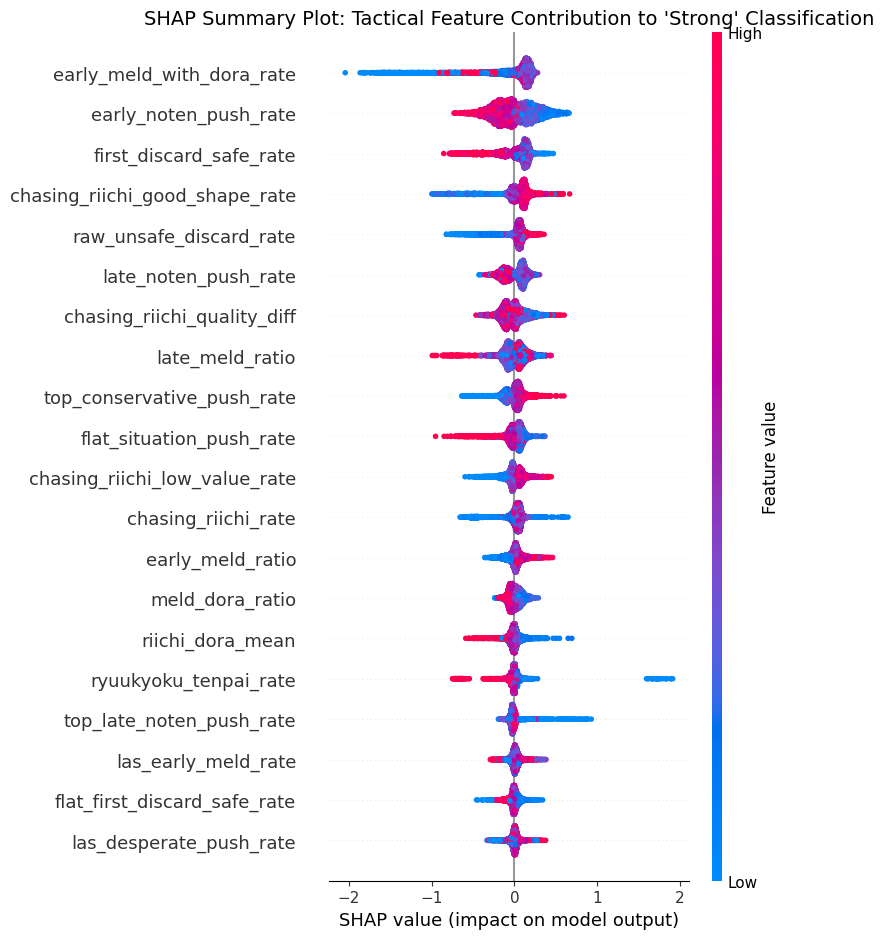

<Figure size 800x600 with 0 Axes>

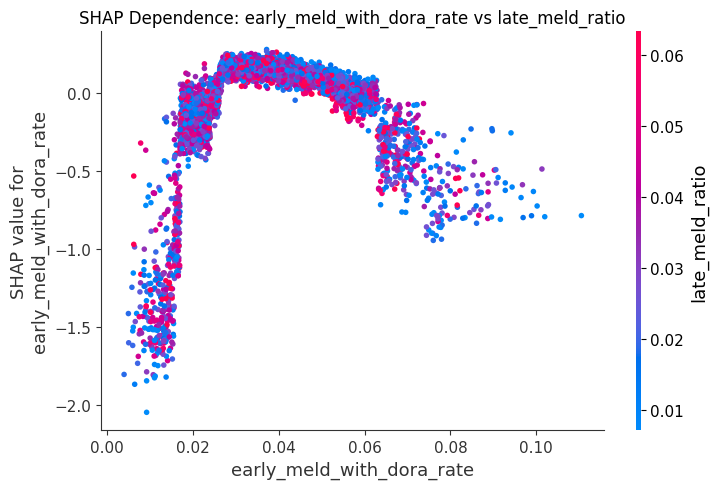

<Figure size 800x600 with 0 Axes>

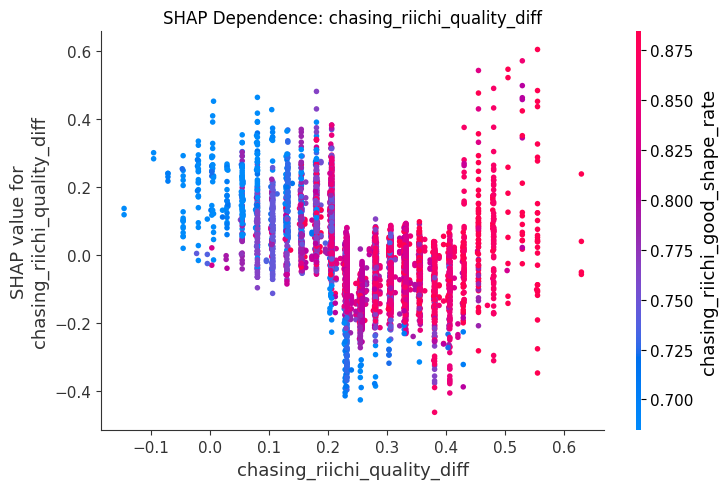

In [24]:


import shap
import matplotlib.pyplot as plt

# ==============================================================================
# 1. 全データで学習した最終モデルの構築と SHAP Explainer の作成
# ==============================================================================
print("==============================================")
print("🔍 【SHAP解析】22次元モデルの意思決定プロセスの可視化")
print("==============================================")

final_model = lgb.LGBMClassifier(
    objective='binary',
    class_weight='balanced',
    random_state=42,
    n_estimators=200,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    verbosity=-1
)
final_model.fit(X_rolled, y_rolled)

# TreeExplainer（決定木モデル専用の高速・厳密なSHAP計算器）
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_rolled)

# 2値分類の場合、正例（強者: 1）への寄与を表す値を取り出す
if isinstance(shap_values, list):
    shap_vals_target = shap_values[1]
else:
    shap_vals_target = shap_values

# ==============================================================================
# 2. SHAP Summary Plot (Beeswarm Plot) の描画
# ==============================================================================
plt.figure(figsize=(10, 8))
plt.title("SHAP Summary Plot: Tactical Feature Contribution to 'Strong' Classification", fontsize=14)
shap.summary_plot(shap_vals_target, X_rolled, feature_names=all_features_v2, show=False)
plt.tight_layout()
plt.show()

# ==============================================================================
# 3. 重要クロス特徴量の SHAP Dependence Plot (依存度プロット)
# ==============================================================================
# 新規クロス特徴量（ドラ付き序盤仕掛け率）の非線形な影響を可視化
plt.figure(figsize=(8, 6))
shap.dependence_plot(
    "early_meld_with_dora_rate",
    shap_vals_target,
    X_rolled,
    feature_names=all_features_v2,
    interaction_index="late_meld_ratio",
    show=False
)
plt.title("SHAP Dependence: early_meld_with_dora_rate vs late_meld_ratio", fontsize=12)
plt.tight_layout()
plt.show()

# 追っかけリーチ精度の依存度プロット
plt.figure(figsize=(8, 6))
shap.dependence_plot(
    "chasing_riichi_quality_diff",  # ← ここを chasing_riichi_quality_diff に修正
    shap_vals_target,
    X_rolled,
    feature_names=all_features_v2,
    interaction_index="chasing_riichi_good_shape_rate",
    show=False
)
plt.title("SHAP Dependence: chasing_riichi_quality_diff", fontsize=12)
plt.tight_layout()
plt.show()

In [25]:
# ==============================================================================
# 🔍 左端高評価サンプル（diff ≈ 0 ＆ 高SHAP）の追っかけリーチ率の検証
# ==============================================================================

# 1. 左端高評価サンプルのマスクを作成
# （chasing_riichi_quality_diff が 0.1未満 かつ SHAP値が 0.15より大きいサンプル群）
diff_col_idx = X_rolled.columns.get_loc('chasing_riichi_quality_diff')
left_high_shap_mask = (
    (X_rolled['chasing_riichi_quality_diff'] < 0.1) &
    (shap_vals_target[:, diff_col_idx] > 0.15)
)

print("--- 検証結果 ---")
print(f"対象グループ（左端高評価サンプル）の数: {left_high_shap_mask.sum()} サンプル")
print("対象グループの平均追っかけリーチ率:", X_rolled.loc[left_high_shap_mask, 'chasing_riichi_rate'].mean())
print("データ全体全体の平均追っかけリーチ率  :", X_rolled['chasing_riichi_rate'].mean())

--- 検証結果 ---
対象グループ（左端高評価サンプル）の数: 171 サンプル
対象グループの平均追っかけリーチ率: 0.07842778700726852
データ全体全体の平均追っかけリーチ率  : 0.057649342115380406


In [26]:
print("==============================================")
print("🔍 データセットのカラム構造チェック")
print("==============================================")

# 1. カラムの一覧を表示
print("■ カラム一覧:")
print(list(micro_dataset_df.columns))

# 2. もしプレイヤーIDやユーザーIDになりそうな列があれば、そのユニーク数を確認
potential_id_cols = [col for col in micro_dataset_df.columns if 'id' in col.lower() or 'player' in col.lower() or 'user' in col.lower() or 'uuid' in col.lower()]
if potential_id_cols:
    print(f"\n■ ID関連と思われる列が見つかりました: {potential_id_cols}")
    for col in potential_id_cols:
        print(f"  - '{col}' のユニーク数: {micro_dataset_df[col].nunique()} (総サンプル数: {len(micro_dataset_df)})")
else:
    print("\n⚠️ 'id' や 'player' を含む列名が見当たりません。")

🔍 データセットのカラム構造チェック
■ カラム一覧:
['file_id', 'total_rounds', 'total_agari', 'total_hoju', 'shobon_dan', 'target_label', 'first_discard_raw_unsafe_rate', 'first_discard_safe_rate', 'early_noten_push_rate', 'mid_noten_push_rate', 'late_noten_push_rate', 'las_desperate_push_rate', 'top_conservative_push_rate', 'flat_situation_push_rate', 'riichi_dora_mean', 'chasing_riichi_good_shape_rate', 'chasing_riichi_low_value_rate', 'chasing_riichi_rate', 'early_meld_ratio', 'late_meld_ratio', 'meld_dora_ratio', 'raw_unsafe_discard_rate', 'ryuukyoku_tenpai_rate', 'ryuukyoku_noten_safe_rate', 'top_late_noten_push_rate', 'las_early_meld_rate', 'early_meld_with_dora_rate', 'chasing_riichi_quality_diff', 'flat_first_discard_safe_rate']

■ ID関連と思われる列が見つかりました: ['file_id', 'mid_noten_push_rate']
  - 'file_id' のユニーク数: 6015 (総サンプル数: 6015)
  - 'mid_noten_push_rate' のユニーク数: 162 (総サンプル数: 6015)


In [27]:
print("==============================================")
print("🔍 実際にモデルに入れている特徴量（all_features_v2）の確認")
print("==============================================")
for i, col in enumerate(all_features_v2, 1):
    print(f"{i}: {col}")

🔍 実際にモデルに入れている特徴量（all_features_v2）の確認
1: first_discard_raw_unsafe_rate
2: first_discard_safe_rate
3: early_noten_push_rate
4: mid_noten_push_rate
5: late_noten_push_rate
6: las_desperate_push_rate
7: top_conservative_push_rate
8: flat_situation_push_rate
9: riichi_dora_mean
10: chasing_riichi_good_shape_rate
11: chasing_riichi_low_value_rate
12: chasing_riichi_rate
13: early_meld_ratio
14: late_meld_ratio
15: meld_dora_ratio
16: raw_unsafe_discard_rate
17: ryuukyoku_tenpai_rate
18: ryuukyoku_noten_safe_rate
19: top_late_noten_push_rate
20: las_early_meld_rate
21: early_meld_with_dora_rate
22: chasing_riichi_quality_diff
23: flat_first_discard_safe_rate


In [32]:
# ============================================================
# 1. ウルトラ立直の牌譜を読み込み、各対局の席順を特定
# ============================================================

import xml.etree.ElementTree as ET
import zipfile
import gzip
import urllib.parse
import pandas as pd
import numpy as np
import gc

# ウルトラ立直の牌譜
ultra_zip_path = '/content/drive/MyDrive/卒論/ultrareach.zip'

# 対象プレイヤー
target_player_name = 'ウルトラ立直'

ultra_seat_map = {}

print("ウルトラ立直の席順を特定しています...")

with zipfile.ZipFile(ultra_zip_path, 'r') as z:

    # ZIP内の牌譜ファイルを取得
    file_list = sorted([
        name for name in z.namelist()
        if name.endswith('.mjlog')
    ])

    for idx, file_name in enumerate(file_list):

        with z.open(file_name) as f:
            content = gzip.decompress(f.read())

        # 空のファイルはスキップ
        if not content:
            continue

        root = ET.fromstring(content)

        # UNタグからプレイヤー名を取得
        for child in root:

            if child.tag != 'UN':
                continue

            for seat in range(4):

                raw_name = child.attrib.get(f'n{seat}', '')
                decoded_name = urllib.parse.unquote(
                    str(raw_name)
                )

                if target_player_name in decoded_name:
                    ultra_seat_map[file_name] = seat
                    break

            break

        if (idx + 1) % 1000 == 0:
            print(f'{idx + 1} / {len(file_list)} 対局を確認')

        del root, content

        if (idx + 1) % 500 == 0:
            gc.collect()

print("\n========== 席順特定結果 ==========")
print(f"ZIP内の牌譜数: {len(file_list)}")
print(f"本人を特定できた対局数: {len(ultra_seat_map)}")
print(
    f"本人を特定できなかった対局数: "
    f"{len(file_list) - len(ultra_seat_map)}"
)

print("\n席順の内訳")
print(
    pd.Series(ultra_seat_map.values())
    .value_counts()
    .sort_index()
)

ウルトラ立直の席順を特定しています...
7000 / 12764 対局を確認
8000 / 12764 対局を確認
9000 / 12764 対局を確認
10000 / 12764 対局を確認
11000 / 12764 対局を確認
12000 / 12764 対局を確認

========== 席順特定結果 ==========
ZIP内の牌譜数: 12764
本人を特定できた対局数: 6053
本人を特定できなかった対局数: 6711

席順の内訳
0    1471
1    1518
2    1541
3    1523
Name: count, dtype: int64


In [34]:
# ============================================================
# 2. ウルトラ立直の特徴量抽出対象を作成
# ============================================================

# 席順を特定できた対局だけを対象にする
ultra_target_df = pd.DataFrame({
    'file_id': sorted(ultra_seat_map.keys())
})

print("========== 特徴量抽出対象 ==========")
print(f"対象対局数: {len(ultra_target_df)}")
print(ultra_target_df.head())

========== 特徴量抽出対象 ==========
対象対局数: 6053
                                             file_id
0  mjlog_pf4-20_n10/2012111923gm-00a9-0000-756d63...
1  mjlog_pf4-20_n10/2012112000gm-00a9-0000-788c56...
2  mjlog_pf4-20_n10/2012112000gm-00a9-0000-c7157d...
3  mjlog_pf4-20_n10/2012112001gm-00a9-0000-6fb5e9...
4  mjlog_pf4-20_n10/2012112018gm-00a9-0000-aec70e...


In [35]:
# ============================================================
# 3. ウルトラ立直のミクロ戦術特徴量を抽出
# ============================================================

ultra_micro_features_df = extract_micro_tactical_features(
    ultra_zip_path,
    ultra_target_df,
    ultra_seat_map
)

print("\n========== 特徴量抽出結果 ==========")
print(f"データ形状: {ultra_micro_features_df.shape}")
print(ultra_micro_features_df.head())

🚀 6,015試合の牌譜から18のミクロ戦術特徴量を一括抽出中...
   進捗: 500 / 6053 試合完了...
   進捗: 1000 / 6053 試合完了...
   進捗: 1500 / 6053 試合完了...
   進捗: 2000 / 6053 試合完了...
   進捗: 2500 / 6053 試合完了...
   進捗: 3000 / 6053 試合完了...
   進捗: 3500 / 6053 試合完了...
   進捗: 4000 / 6053 試合完了...
   進捗: 4500 / 6053 試合完了...
   進捗: 5000 / 6053 試合完了...
   進捗: 5500 / 6053 試合完了...
   進捗: 6000 / 6053 試合完了...

========== 特徴量抽出結果 ==========
データ形状: (6053, 19)
                                             file_id  \
0  mjlog_pf4-20_n10/2012120714gm-00a9-0000-e9d531...   
1  mjlog_pf4-20_n10/2014070609gm-00a9-0000-efad0e...   
2  mjlog_pf4-20_n10/2013072106gm-00a9-0000-c15bd8...   
3  mjlog_pf4-20_n10/2014112223gm-00a9-0000-b46f6e...   
4  mjlog_pf4-20_n10/2014082300gm-00a9-0000-4d1545...   

   first_discard_raw_unsafe_rate  first_discard_safe_rate  \
0                            NaN                      NaN   
1                       0.333333                 0.555556   
2                       0.000000                 0.666667   
3           

In [36]:
# ============================================================
# 4. ウルトラ立直の特徴量を結合し、クロス特徴量を作成
# ============================================================

# 元の対局情報と特徴量を結合
ultra_dataset_df = pd.merge(
    ultra_target_df,
    ultra_micro_features_df,
    on='file_id',
    how='inner',
    validate='one_to_one'
)

# クロス特徴量を追加
ultra_dataset_df['top_late_noten_push_rate'] = (
    ultra_dataset_df['top_conservative_push_rate']
    * ultra_dataset_df['late_noten_push_rate']
)

ultra_dataset_df['las_early_meld_rate'] = (
    ultra_dataset_df['las_desperate_push_rate']
    * ultra_dataset_df['early_meld_ratio']
)

ultra_dataset_df['early_meld_with_dora_rate'] = (
    ultra_dataset_df['early_meld_ratio']
    * ultra_dataset_df['meld_dora_ratio']
)

ultra_dataset_df['chasing_riichi_quality_diff'] = (
    ultra_dataset_df['chasing_riichi_good_shape_rate']
    - ultra_dataset_df['chasing_riichi_low_value_rate']
)

ultra_dataset_df['flat_first_discard_safe_rate'] = (
    ultra_dataset_df['first_discard_safe_rate']
    * (1.0 - ultra_dataset_df['flat_situation_push_rate'])
)

print("========== クロス特徴量作成完了 ==========")
print(f"データ形状: {ultra_dataset_df.shape}")

========== クロス特徴量作成完了 ==========
データ形状: (6053, 24)


In [38]:
# ============================================================
# 5. 学習済みモデルによるウルトラ立直の強弱分類
# ============================================================

from sklearn.metrics import classification_report
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# ① 学習時の特徴量名を確認
# ------------------------------------------------------------

feature_cols = list(all_features_v2)

assert len(feature_cols) == 23, (
    f"想定は23特徴量ですが、実際は{len(feature_cols)}個です"
)

missing_cols = [
    col for col in feature_cols
    if col not in ultra_dataset_df.columns
]

if missing_cols:
    raise ValueError(
        f"ウルトラ立直のデータに不足している特徴量: {missing_cols}"
    )

# ------------------------------------------------------------
# ② 学習データの平均値で欠損値を補完
# ------------------------------------------------------------

# 元の学習データから特徴量ごとの平均値を取得
train_feature_means = micro_dataset_df[feature_cols].mean()

# 特徴量抽出時の欠損値を学習データの平均値で補完
X_ultra = ultra_dataset_df[feature_cols].copy()

X_ultra = X_ultra.replace([np.inf, -np.inf], np.nan)
X_ultra = X_ultra.fillna(train_feature_means)

# 学習時と同じ列順に統一
X_ultra = X_ultra[feature_cols]

# ------------------------------------------------------------
# ③ 対局順に10試合移動平均を適用
# ------------------------------------------------------------

# file_idの順序で並べる
sort_idx = ultra_dataset_df['file_id'].sort_values().index

ultra_dataset_df = (
    ultra_dataset_df.loc[sort_idx]
    .reset_index(drop=True)
)

X_ultra = X_ultra.loc[sort_idx].reset_index(drop=True)

# 学習時と同じwindow=10, min_periods=1
X_ultra_rolled = X_ultra.rolling(
    window=10,
    min_periods=1
).mean()

# ------------------------------------------------------------
# ④ 学習済みモデルで予測
# ------------------------------------------------------------

# 重要：ここではfit()を呼ばない
ultra_pred_proba = final_model.predict_proba(
    X_ultra_rolled
)[:, 1]

# 強(1)・弱(0)の予測ラベル
ultra_pred_label = (
    ultra_pred_proba >= 0.5
).astype(int)

# ------------------------------------------------------------
# ⑤ 結果を保存
# ------------------------------------------------------------

ultra_results_df = ultra_dataset_df[
    ['file_id']
].copy()

ultra_results_df['strong_probability'] = ultra_pred_proba
ultra_results_df['predicted_label'] = ultra_pred_label

ultra_results_df['predicted_class'] = np.where(
    ultra_pred_label == 1,
    '強 (1)',
    '弱 (0)'
)

print("========== 分類結果 ==========")
print(f"分類対象の対局数: {len(ultra_results_df)}")

print("\n分類結果の件数")
print(ultra_results_df['predicted_class'].value_counts())

print("\n分類結果の割合")
print(
    ultra_results_df['predicted_class']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .astype(str)
    + '%'
)

print(
    "\n強判定確率の平均:",
    round(ultra_results_df['strong_probability'].mean(), 4)
)

print("\n結果の先頭10件")
display(ultra_results_df.head(10))

# CSVに保存
output_path = (
    '/content/drive/MyDrive/卒論/'
    'ultrareach_classification_results.csv'
)

ultra_results_df.to_csv(
    output_path,
    index=False,
    encoding='utf-8-sig'
)

print(f"\n結果を保存しました: {output_path}")

========== 分類結果 ==========
分類対象の対局数: 6053

分類結果の件数
predicted_class
弱 (0)    4404
強 (1)    1649
Name: count, dtype: int64

分類結果の割合
predicted_class
弱 (0)    72.76%
強 (1)    27.24%
Name: proportion, dtype: object

強判定確率の平均: 0.3882

結果の先頭10件


,file_id,strong_probability,predicted_label,predicted_class
0,mjlog_pf4-20_n10/2012111923gm-00a9-0000-756d63...,0.061034,0,弱 (0)
1,mjlog_pf4-20_n10/2012112000gm-00a9-0000-788c56...,0.241577,0,弱 (0)
2,mjlog_pf4-20_n10/2012112000gm-00a9-0000-c7157d...,0.453259,0,弱 (0)
3,mjlog_pf4-20_n10/2012112001gm-00a9-0000-6fb5e9...,0.446596,0,弱 (0)
4,mjlog_pf4-20_n10/2012112018gm-00a9-0000-aec70e...,0.242829,0,弱 (0)
5,mjlog_pf4-20_n10/2012112022gm-00a9-0000-d69584...,0.118974,0,弱 (0)
6,mjlog_pf4-20_n10/2012112023gm-00a9-0000-164018...,0.359796,0,弱 (0)
7,mjlog_pf4-20_n10/2012112023gm-00a9-0000-d67e6f...,0.170216,0,弱 (0)
8,mjlog_pf4-20_n10/2012112100gm-00a9-0000-5d58ed...,0.164149,0,弱 (0)
9,mjlog_pf4-20_n10/2012112219gm-00a9-0000-c41540...,0.368378,0,弱 (0)



結果を保存しました: /content/drive/MyDrive/卒論/ultrareach_classification_results.csv


In [39]:
# ==============================================================================
# ウルトラ立直の正解ラベル作成と分類モデルの評価
# ==============================================================================

import xml.etree.ElementTree as ET
import pandas as pd
import numpy as np
import zipfile
import gzip
import urllib.parse
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score
)

# ------------------------------------------------------------------------------
# 1. ファイルパス
# ------------------------------------------------------------------------------

zip_path = '/content/drive/MyDrive/卒論/ultrareach.zip'
results_path = '/content/drive/MyDrive/卒論/ultrareach_classification_results.csv'

# 先ほどの分類結果を読み込む
ultra_results = pd.read_csv(results_path)

print("分類結果の読み込み完了")
print(f"予測結果の件数: {len(ultra_results)}")


# ------------------------------------------------------------------------------
# 2. ウルトラ立直の段位を各対局から抽出
# ------------------------------------------------------------------------------

print("\nウルトラ立直の段位を抽出しています...")

dan_rows = []
valid_file_ids = []

with zipfile.ZipFile(zip_path, 'r') as z:

    file_list = sorted(
        f for f in z.namelist()
        if f.endswith('.mjlog')
    )

    for file_name in file_list:

        # ファイルの読み込み
        with z.open(file_name) as f:
            raw_content = f.read()

        # 空ファイルは除外
        if not raw_content:
            continue

        # gzip形式を展開。gzipでなければ元データを使用
        try:
            content = gzip.decompress(raw_content)
        except (gzip.BadGzipFile, EOFError, OSError):
            content = raw_content

        # XML解析に失敗したファイルは除外
        try:
            root = ET.fromstring(content)
        except ET.ParseError:
            continue

        # 正常に読み込めた対局を記録
        valid_file_ids.append(file_name)

        # UNタグから本人の席順と段位を取得
        for child in root:

            if child.tag != 'UN':
                continue

            names = [
                urllib.parse.unquote(str(child.attrib.get(f'n{i}', '')))
                for i in range(4)
            ]

            ultra_seats = [
                i for i, name in enumerate(names)
                if 'ウルトラ立直' in name
            ]

            if not ultra_seats:
                continue

            # 本人の席順
            seat = ultra_seats[0]

            # 段位情報
            dan_raw = str(child.attrib.get('dan', ''))
            dan_list = dan_raw.split(',')

            if seat >= len(dan_list) or dan_list[seat] == '':
                break

            try:
                dan_value = float(dan_list[seat])
            except (ValueError, TypeError):
                break

            dan_rows.append({
                'file_id': file_name,
                'ultra_dan': dan_value
            })

            break


# ------------------------------------------------------------------------------
# 3. 対局順を整理し、最初の1,500対局を除外
# ------------------------------------------------------------------------------

valid_games_df = pd.DataFrame({
    'file_id': sorted(set(valid_file_ids))
})

valid_games_df = (
    valid_games_df
    .sort_values('file_id')
    .reset_index(drop=True)
)

# しょぼんnのコードと同様に初期1,500対局を除外
valid_games_df = valid_games_df.iloc[1500:].copy()

dan_df = pd.DataFrame(dan_rows)

# 初期1,500対局を除外した対象と段位情報を結合
ultra_target_df = valid_games_df.merge(
    dan_df,
    on='file_id',
    how='left'
)

# ------------------------------------------------------------------------------
# 4. 段位から正解ラベルを作成
# ------------------------------------------------------------------------------

ultra_target_df['target_label'] = np.select(
    [
        ultra_target_df['ultra_dan'] >= 18,
        ultra_target_df['ultra_dan'] <= 16
    ],
    [
        1,  # 強
        0   # 弱
    ],
    default=np.nan
)

# 段位17および段位情報が取得できなかった対局を除外
ultra_target_df = ultra_target_df.dropna(
    subset=['target_label']
).copy()

ultra_target_df['target_label'] = (
    ultra_target_df['target_label'].astype(int)
)

print("\n正解ラベルの作成完了")
print("正解ラベルの件数:")
print(ultra_target_df['target_label'].value_counts().sort_index())

print(f"\n正解ラベル付き対局数: {len(ultra_target_df)}")


# ------------------------------------------------------------------------------
# 5. 正解ラベルと予測結果を結合
# ------------------------------------------------------------------------------

eval_df = ultra_target_df[
    ['file_id', 'ultra_dan', 'target_label']
].merge(
    ultra_results[
        ['file_id', 'predicted_label', 'strong_probability']
    ],
    on='file_id',
    how='inner'
)

# 欠損値を除外
eval_df = eval_df.dropna(
    subset=['target_label', 'predicted_label']
).copy()

eval_df['target_label'] = eval_df['target_label'].astype(int)
eval_df['predicted_label'] = eval_df['predicted_label'].astype(int)

if len(eval_df) == 0:
    raise ValueError(
        "評価対象が0件です。file_idの形式や段位の抽出結果を確認してください。"
    )


# ------------------------------------------------------------------------------
# 6. 評価指標を計算
# ------------------------------------------------------------------------------

y_true = eval_df['target_label']
y_pred = eval_df['predicted_label']

accuracy = accuracy_score(y_true, y_pred)
balanced_accuracy = balanced_accuracy_score(y_true, y_pred)

print("\n" + "=" * 55)
print("ウルトラ立直：分類モデルの評価結果")
print("=" * 55)

print(f"評価対象の対局数: {len(eval_df)}")
print(f"正解率 (Accuracy): {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(
    f"バランス正解率 (Balanced Accuracy): "
    f"{balanced_accuracy:.4f} ({balanced_accuracy * 100:.2f}%)"
)

print("\n混同行列（行：正解ラベル、列：予測ラベル）")
print("順番：弱 (0)、強 (1)")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\n分類レポート")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=['弱 (0)', '強 (1)'],
        zero_division=0
    )
)

print("\n正解ラベルの割合")
print(
    eval_df['target_label']
    .value_counts(normalize=True)
    .sort_index()
    .rename(index={0: '弱 (0)', 1: '強 (1)'})
    .map(lambda x: f'{x:.2%}')
)

print("\n予測ラベルの割合")
print(
    eval_df['predicted_label']
    .value_counts(normalize=True)
    .sort_index()
    .rename(index={0: '弱 (0)', 1: '強 (1)'})
    .map(lambda x: f'{x:.2%}')
)


# ------------------------------------------------------------------------------
# 7. 評価結果を保存
# ------------------------------------------------------------------------------

output_path = (
    '/content/drive/MyDrive/卒論/'
    'ultrareach_evaluation_results.csv'
)

eval_df.to_csv(output_path, index=False, encoding='utf-8-sig')

print(f"\n評価データを保存しました: {output_path}")

分類結果の読み込み完了
予測結果の件数: 6053

ウルトラ立直の段位を抽出しています...

正解ラベルの作成完了
正解ラベルの件数:
target_label
0     257
1    1488
Name: count, dtype: int64

正解ラベル付き対局数: 1745

ウルトラ立直：分類モデルの評価結果
評価対象の対局数: 1745
正解率 (Accuracy): 0.3559 (35.59%)
バランス正解率 (Balanced Accuracy): 0.5080 (50.80%)

混同行列（行：正解ラベル、列：予測ラベル）
順番：弱 (0)、強 (1)
[[ 186   71]
 [1053  435]]

分類レポート
              precision    recall  f1-score   support

       弱 (0)       0.15      0.72      0.25       257
       強 (1)       0.86      0.29      0.44      1488

    accuracy                           0.36      1745
   macro avg       0.50      0.51      0.34      1745
weighted avg       0.76      0.36      0.41      1745


正解ラベルの割合
target_label
弱 (0)    14.73%
強 (1)    85.27%
Name: proportion, dtype: object

予測ラベルの割合
predicted_label
弱 (0)    71.00%
強 (1)    29.00%
Name: proportion, dtype: object

評価データを保存しました: /content/drive/MyDrive/卒論/ultrareach_evaluation_results.csv


In [40]:
# ============================================================
# ウルトラ立直の正解ラベルと予測結果の対応を確認
# ============================================================

import pandas as pd
import numpy as np

# 1. 正解ラベルと予測結果を結合
check_df = ultra_target_df[
    ['file_id', 'ultra_dan', 'target_label']
].merge(
    ultra_results_df[
        ['file_id', 'strong_probability', 'predicted_label']
    ],
    on='file_id',
    how='inner',
    validate='one_to_one'
)

# 2. 評価対象を確認
print("========== 対応確認 ==========")
print(f"正解ラベル付き対局数: {len(ultra_target_df)}")
print(f"予測結果の対局数: {len(ultra_results_df)}")
print(f"結合できた対局数: {len(check_df)}")

# 3. 段位と正解ラベルの対応を確認
print("\n========== 段位と正解ラベル ==========")

print(
    check_df.groupby('target_label')['ultra_dan']
    .agg(['min', 'max', 'count'])
)

# 4. 段位別の予測結果を確認
print("\n========== 段位別の予測結果 ==========")

check_df['predicted_label'] = (
    check_df['predicted_label'].astype(int)
)

print(
    pd.crosstab(
        check_df['ultra_dan'],
        check_df['predicted_label'],
        margins=True
    )
)

# 5. 時系列順の先頭・末尾を確認
print("\n========== 時系列順の確認 ==========")

check_df = check_df.sort_values('file_id')

display(
    check_df[
        [
            'file_id',
            'ultra_dan',
            'target_label',
            'strong_probability',
            'predicted_label'
        ]
    ].head(10)
)

display(
    check_df[
        [
            'file_id',
            'ultra_dan',
            'target_label',
            'strong_probability',
            'predicted_label'
        ]
    ].tail(10)
)

========== 対応確認 ==========
正解ラベル付き対局数: 1745
予測結果の対局数: 6053
結合できた対局数: 1745

========== 段位と正解ラベル ==========
               min   max  count
target_label                   
0             16.0  16.0    257
1             18.0  20.0   1488

========== 段位別の予測結果 ==========
predicted_label     0    1   All
ultra_dan                       
16.0              186   71   257
18.0             1002  410  1412
19.0               51   24    75
20.0                0    1     1
All              1239  506  1745

========== 時系列順の確認 ==========


,file_id,ultra_dan,target_label,strong_probability,predicted_label
0,mjlog_pf4-20_n10/2014011610gm-00a9-0000-dc5eb8...,18.0,1,0.457518,0
1,mjlog_pf4-20_n10/2014011902gm-00a9-0000-4747b7...,18.0,1,0.293751,0
2,mjlog_pf4-20_n10/2014011911gm-00a9-0000-7b96e2...,18.0,1,0.412954,0
3,mjlog_pf4-20_n10/2014011911gm-00a9-0000-a2ec0e...,18.0,1,0.347731,0
4,mjlog_pf4-20_n10/2014011912gm-00a9-0000-3f8cd3...,18.0,1,0.193829,0
5,mjlog_pf4-20_n10/2014011913gm-00a9-0000-d6d5d5...,18.0,1,0.257265,0
6,mjlog_pf4-20_n10/2014011916gm-00a9-0000-5a24d3...,18.0,1,0.463193,0
7,mjlog_pf4-20_n10/2014011916gm-00a9-0000-623a2c...,18.0,1,0.389163,0
8,mjlog_pf4-20_n10/2014011917gm-00a9-0000-ac261e...,18.0,1,0.405854,0
9,mjlog_pf4-20_n10/2014011922gm-00a9-0000-47c39a...,18.0,1,0.277516,0


,file_id,ultra_dan,target_label,strong_probability,predicted_label
1735,mjlog_pf4-20_n10/2016082109gm-00a9-0000-1d1cef...,19.0,1,0.518045,1
1736,mjlog_pf4-20_n10/2016082110gm-00a9-0000-4daada...,19.0,1,0.592160,1
1737,mjlog_pf4-20_n10/2016082110gm-00a9-0000-53605b...,19.0,1,0.611839,1
1738,mjlog_pf4-20_n10/2016082110gm-00a9-0000-dc03b6...,19.0,1,0.514910,1
1739,mjlog_pf4-20_n10/2016082112gm-00a9-0000-627bf9...,19.0,1,0.363497,0
1740,mjlog_pf4-20_n10/2016082112gm-00a9-0000-de3c98...,19.0,1,0.496053,0
1741,mjlog_pf4-20_n10/2016082113gm-00a9-0000-2507b9...,19.0,1,0.429763,0
1742,mjlog_pf4-20_n10/2016082113gm-00a9-0000-440242...,19.0,1,0.533320,1
1743,mjlog_pf4-20_n10/2016082114gm-00a9-0000-5a7395...,19.0,1,0.672999,1
1744,mjlog_pf4-20_n10/2016082221gm-00a9-0000-ebc657...,20.0,1,0.618471,1


In [41]:
# ============================================================
# しょぼんnの学習データの並び順を確認
# ============================================================

print("========== micro_dataset_df の確認 ==========")

print("データ件数:", len(micro_dataset_df))

print("\n先頭10件の file_id")
print(micro_dataset_df['file_id'].head(10).to_list())

print("\n末尾10件の file_id")
print(micro_dataset_df['file_id'].tail(10).to_list())

# file_id順に並んでいるかを確認
is_sorted = micro_dataset_df['file_id'].is_monotonic_increasing

print("\nfile_idが昇順か:", is_sorted)

# 現在の順序とfile_id昇順の順位を比較
current_order = micro_dataset_df['file_id'].reset_index(drop=True)
sorted_order = micro_dataset_df['file_id'].sort_values().reset_index(drop=True)

print(
    "現在の順序とfile_id昇順が完全一致するか:",
    current_order.equals(sorted_order)
)

========== micro_dataset_df の確認 ==========
データ件数: 6015

先頭10件の file_id
['mjlog_pf4-20_n30/2012062303gm-0029-0000-bb2d01c5&tw=0.mjlog', 'mjlog_pf4-20_n30/2012062304gm-0029-0000-dff1fa7e&tw=0.mjlog', 'mjlog_pf4-20_n30/2012062311gm-0029-0000-f8bbd45f&tw=1.mjlog', 'mjlog_pf4-20_n30/2012062312gm-0029-0000-006c5ee0&tw=1.mjlog', 'mjlog_pf4-20_n30/2012062316gm-0029-0000-c3810c0f&tw=0.mjlog', 'mjlog_pf4-20_n30/2012062317gm-0029-0000-94e13395&tw=2.mjlog', 'mjlog_pf4-20_n30/2012062318gm-0029-0000-e26b3cd9&tw=2.mjlog', 'mjlog_pf4-20_n30/2012062422gm-0029-0000-5d7681c0&tw=1.mjlog', 'mjlog_pf4-20_n30/2012062422gm-0029-0000-5dfa64d8&tw=1.mjlog', 'mjlog_pf4-20_n30/2012062423gm-0029-0000-3de5f15c&tw=2.mjlog']

末尾10件の file_id
['mjlog_pf4-20_n30/2026050519gm-00a9-0000-5a7ac654&tw=3.mjlog', 'mjlog_pf4-20_n30/2026050520gm-00a9-0000-1fbe9dee&tw=2.mjlog', 'mjlog_pf4-20_n30/2026050521gm-00a9-0000-14132cef&tw=1.mjlog', 'mjlog_pf4-20_n30/2026050609gm-00a9-0000-29d5cd3b&tw=2.mjlog', 'mjlog_pf4-20_n30/2026050610g

In [42]:
# 学習データの欠損値・無限大
X_train_raw = micro_dataset_df[all_features_v2].copy()

print("========== しょぼんn：学習データ ==========")
print("欠損値の総数:", X_train_raw.isna().sum().sum())
print("無限大の総数:", np.isinf(X_train_raw).sum().sum())

print("\n欠損値がある特徴量")
print(X_train_raw.isna().sum()[X_train_raw.isna().sum() > 0])

# ウルトラ立直の欠損値・無限大
X_ultra_raw = ultra_dataset_df[all_features_v2].copy()

print("\n========== ウルトラ立直：予測データ ==========")
print("欠損値の総数:", X_ultra_raw.isna().sum().sum())
print("無限大の総数:", np.isinf(X_ultra_raw).sum().sum())

print("\n欠損値がある特徴量")
print(X_ultra_raw.isna().sum()[X_ultra_raw.isna().sum() > 0])

========== しょぼんn：学習データ ==========
欠損値の総数: 0
無限大の総数: 0

欠損値がある特徴量
Series([], dtype: int64)

========== ウルトラ立直：予測データ ==========
欠損値の総数: 37471
無限大の総数: 0

欠損値がある特徴量
first_discard_raw_unsafe_rate       53
first_discard_safe_rate             53
early_noten_push_rate             2558
mid_noten_push_rate                528
late_noten_push_rate              1551
las_desperate_push_rate           3890
top_conservative_push_rate        1430
flat_situation_push_rate          1420
riichi_dora_mean                  1167
chasing_riichi_good_shape_rate    4876
chasing_riichi_low_value_rate     4876
chasing_riichi_rate                 53
raw_unsafe_discard_rate             72
ryuukyoku_tenpai_rate             1148
ryuukyoku_noten_safe_rate         1148
top_late_noten_push_rate          2462
las_early_meld_rate               3890
chasing_riichi_quality_diff       4876
flat_first_discard_safe_rate      1420
dtype: int64


In [43]:
# ============================================================
# ウルトラ立直：元特徴量と派生特徴量の欠損率を確認
# ============================================================

derived_features = [
    'top_late_noten_push_rate',
    'las_early_meld_rate',
    'early_meld_with_dora_rate',
    'chasing_riichi_quality_diff',
    'flat_first_discard_safe_rate'
]

base_features = [
    col for col in all_features_v2
    if col not in derived_features
]

print("========== 元特徴量の欠損率 ==========")

base_missing = (
    ultra_dataset_df[base_features]
    .isna()
    .mean()
    .sort_values(ascending=False)
)

display(
    (base_missing * 100)
    .round(2)
    .rename("欠損率（%）")
    .to_frame()
)

print("\n========== 派生特徴量の欠損率 ==========")

derived_missing = (
    ultra_dataset_df[derived_features]
    .isna()
    .mean()
    .sort_values(ascending=False)
)

display(
    (derived_missing * 100)
    .round(2)
    .rename("欠損率（%）")
    .to_frame()
)

========== 元特徴量の欠損率 ==========


,欠損率（%）
chasing_riichi_low_value_rate,80.56
chasing_riichi_good_shape_rate,80.56
las_desperate_push_rate,64.27
early_noten_push_rate,42.26
late_noten_push_rate,25.62
top_conservative_push_rate,23.62
flat_situation_push_rate,23.46
riichi_dora_mean,19.28
ryuukyoku_tenpai_rate,18.97
ryuukyoku_noten_safe_rate,18.97



========== 派生特徴量の欠損率 ==========


,欠損率（%）
chasing_riichi_quality_diff,80.56
las_early_meld_rate,64.27
top_late_noten_push_rate,40.67
flat_first_discard_safe_rate,23.46
early_meld_with_dora_rate,0.00


In [44]:
import inspect

print(inspect.getsource(extract_micro_tactical_features))

def extract_micro_tactical_features(zip_path, target_df, shobon_map):
    print("🚀 6,015試合の牌譜から18のミクロ戦術特徴量を一括抽出中...")
    target_files = set(target_df['file_id'].unique())
    features_list = []

    draw_prefixes = ('T', 'U', 'V', 'W')
    discard_prefixes = ('D', 'E', 'F', 'G')

    with zipfile.ZipFile(zip_path, 'r') as z:
        for idx, file_name in enumerate(target_files):
            if idx > 0 and idx % 500 == 0:
                print(f"   進捗: {idx} / {len(target_files)} 試合完了...")

            with z.open(file_name) as f:
                content = gzip.decompress(f.read())
                root = ET.fromstring(content)

                my_seat = shobon_map.get(file_name, -1)
                if my_seat == -1:
                    continue

                # --- 試合ごとのミクロ集計カウンター ---
                # 1. 守備のミクロ（一発目）
                first_discard_opp_reach_count = 0
                first_discard_raw_unsafe_count = 0
                first_discard_safe_count = 0

                # 2. 巡

In [45]:
# 学習データの作成前後で、特徴量の欠損値をどう処理しているか確認

print("========== 学習データ ==========")
print("micro_dataset_df:", micro_dataset_df.shape)

print("\n特徴量の欠損数:")
print(
    micro_dataset_df[all_features_v2]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\n特徴量の先頭5行:")
display(micro_dataset_df[all_features_v2].head())

========== 学習データ ==========
micro_dataset_df: (6015, 29)

特徴量の欠損数:
first_discard_raw_unsafe_rate     0
first_discard_safe_rate           0
early_noten_push_rate             0
mid_noten_push_rate               0
late_noten_push_rate              0
las_desperate_push_rate           0
top_conservative_push_rate        0
flat_situation_push_rate          0
riichi_dora_mean                  0
chasing_riichi_good_shape_rate    0
dtype: int64

特徴量の先頭5行:


,first_discard_raw_unsafe_rate,first_discard_safe_rate,early_noten_push_rate,mid_noten_push_rate,late_noten_push_rate,las_desperate_push_rate,top_conservative_push_rate,flat_situation_push_rate,riichi_dora_mean,chasing_riichi_good_shape_rate,...,late_meld_ratio,meld_dora_ratio,raw_unsafe_discard_rate,ryuukyoku_tenpai_rate,ryuukyoku_noten_safe_rate,top_late_noten_push_rate,las_early_meld_rate,early_meld_with_dora_rate,chasing_riichi_quality_diff,flat_first_discard_safe_rate
0,0.333333,0.666667,0.000000,0.200000,0.490837,0.613263,1.000000,0.166667,0.000000,0.807433,...,0.000000,0.272727,0.545455,1.000000,0.000000,0.490837,0.167254,0.074380,0.25737,0.555556
1,0.666667,0.166667,0.000000,0.625000,0.600000,0.613263,1.000000,0.588235,0.511246,0.807433,...,0.090909,0.181818,0.611111,1.000000,0.000000,0.600000,0.111502,0.033058,0.25737,0.068627
2,0.400000,0.400000,0.000000,0.631579,0.333333,0.613263,0.541667,0.538462,1.000000,0.807433,...,0.076923,0.076923,0.540541,0.000000,1.000000,0.180556,0.094348,0.011834,0.25737,0.184615
3,0.333333,0.666667,0.525866,0.166667,0.500000,0.428571,0.539910,0.558740,0.000000,0.807433,...,0.083333,0.500000,0.428571,0.333333,0.666667,0.269955,0.178571,0.208333,0.25737,0.294173
4,0.375000,0.375000,0.525866,0.666667,0.500000,0.613263,0.846154,0.500000,0.511246,0.807433,...,0.000000,0.222222,0.714286,0.412560,0.587440,0.423077,0.340702,0.123457,0.25737,0.187500


In [47]:
import pandas as pd
import numpy as np

# 比較するデータフレーム
train_df = micro_dataset_df
ultra_df = ultra_dataset_df

print("===== 1. データの形状 =====")
print("しょぼんn:", train_df.shape)
print("ウルトラ立直:", ultra_df.shape)

print("\n===== 2. 特徴量の列数 =====")
print("学習用特徴量:", len(all_features_v2))
print("学習データに存在する特徴量:",
      sum(c in train_df.columns for c in all_features_v2))
print("ウルトラ立直に存在する特徴量:",
      sum(c in ultra_df.columns for c in all_features_v2))

print("\n===== 3. 不足している特徴量 =====")
print("学習データにない列:",
      [c for c in all_features_v2 if c not in train_df.columns])
print("ウルトラ立直にない列:",
      [c for c in all_features_v2 if c not in ultra_df.columns])

print("\n===== 4. 欠損値の数 =====")
print("【学習データ】")
print(train_df[all_features_v2].isna().sum().to_string())

print("\n【ウルトラ立直】")
print(ultra_df[all_features_v2].isna().sum().to_string())

print("\n===== 5. データ型の違い =====")
dtype_df = pd.DataFrame({
    "train_dtype": train_df[all_features_v2].dtypes.astype(str),
    "ultra_dtype": ultra_df[all_features_v2].dtypes.astype(str)
})
print(dtype_df[dtype_df["train_dtype"] != dtype_df["ultra_dtype"]])

print("\n===== 6. 特徴量の値の範囲 =====")
for c in all_features_v2:
    print(
        f"{c}: "
        f"学習={train_df[c].min():.4f}～{train_df[c].max():.4f}, "
        f"ウルトラ={ultra_df[c].min():.4f}～{ultra_df[c].max():.4f}"
    )

===== 1. データの形状 =====
しょぼんn: (6015, 29)
ウルトラ立直: (6053, 24)

===== 2. 特徴量の列数 =====
学習用特徴量: 23
学習データに存在する特徴量: 23
ウルトラ立直に存在する特徴量: 23

===== 3. 不足している特徴量 =====
学習データにない列: []
ウルトラ立直にない列: []

===== 4. 欠損値の数 =====
【学習データ】
first_discard_raw_unsafe_rate     0
first_discard_safe_rate           0
early_noten_push_rate             0
mid_noten_push_rate               0
late_noten_push_rate              0
las_desperate_push_rate           0
top_conservative_push_rate        0
flat_situation_push_rate          0
riichi_dora_mean                  0
chasing_riichi_good_shape_rate    0
chasing_riichi_low_value_rate     0
chasing_riichi_rate               0
early_meld_ratio                  0
late_meld_ratio                   0
meld_dora_ratio                   0
raw_unsafe_discard_rate           0
ryuukyoku_tenpai_rate             0
ryuukyoku_noten_safe_rate         0
top_late_noten_push_rate          0
las_early_meld_rate               0
early_meld_with_dora_rate         0
chasing_riichi_quality_diff  

In [48]:
# ==========================================
# 学習データの平均値を使った欠損値補完の確認
# ==========================================

feature_cols = list(all_features_v2)

# 学習データから補完用の平均値を計算
train_feature_means = micro_dataset_df[feature_cols].mean()

# ウルトラ立直の特徴量をコピー
X_ultra_check = ultra_dataset_df[feature_cols].copy()

# 無限大も欠損値として扱う
X_ultra_check = X_ultra_check.replace([np.inf, -np.inf], np.nan)

# 学習データの平均値で補完
X_ultra_check = X_ultra_check.fillna(train_feature_means)

print("===== 補完後の欠損値 =====")
print(X_ultra_check.isna().sum().sum())

print("\n===== 学習データと補完後のデータの平均値 =====")
comparison = pd.DataFrame({
    "train_mean": micro_dataset_df[feature_cols].mean(),
    "ultra_mean_after_fill": X_ultra_check.mean()
})

print(comparison.round(4).to_string())

print("\n===== 補完後の無限大の数 =====")
print(np.isinf(X_ultra_check.to_numpy()).sum())

===== 補完後の欠損値 =====
0

===== 学習データと補完後のデータの平均値 =====
                                train_mean  ultra_mean_after_fill
first_discard_raw_unsafe_rate       0.4279                 0.4128
first_discard_safe_rate             0.4777                 0.4992
early_noten_push_rate               0.5259                 0.5067
mid_noten_push_rate                 0.4882                 0.4883
late_noten_push_rate                0.4908                 0.4829
las_desperate_push_rate             0.6133                 0.6058
top_conservative_push_rate          0.5399                 0.5266
flat_situation_push_rate            0.5587                 0.5498
riichi_dora_mean                    0.5112                 0.5047
chasing_riichi_good_shape_rate      0.8074                 0.8065
chasing_riichi_low_value_rate       0.5501                 0.5538
chasing_riichi_rate                 0.0577                 0.0437
early_meld_ratio                    0.2215                 0.2300
late_meld_ratio        

In [49]:
import inspect

print(inspect.getsource(extract_micro_tactical_features))

def extract_micro_tactical_features(zip_path, target_df, shobon_map):
    print("🚀 6,015試合の牌譜から18のミクロ戦術特徴量を一括抽出中...")
    target_files = set(target_df['file_id'].unique())
    features_list = []

    draw_prefixes = ('T', 'U', 'V', 'W')
    discard_prefixes = ('D', 'E', 'F', 'G')

    with zipfile.ZipFile(zip_path, 'r') as z:
        for idx, file_name in enumerate(target_files):
            if idx > 0 and idx % 500 == 0:
                print(f"   進捗: {idx} / {len(target_files)} 試合完了...")

            with z.open(file_name) as f:
                content = gzip.decompress(f.read())
                root = ET.fromstring(content)

                my_seat = shobon_map.get(file_name, -1)
                if my_seat == -1:
                    continue

                # --- 試合ごとのミクロ集計カウンター ---
                # 1. 守備のミクロ（一発目）
                first_discard_opp_reach_count = 0
                first_discard_raw_unsafe_count = 0
                first_discard_safe_count = 0

                # 2. 巡

In [50]:
# ==========================================
# ウルトラ立直の対象試合・名前の一致を確認
# ==========================================

print("===== 1. 対象試合数 =====")
print("対象試合数:", len(ultra_target_df))

print("\n===== 2. file_id の順序 =====")
print("先頭10件:")
print(ultra_target_df["file_id"].head(10).to_list())

print("\n末尾10件:")
print(ultra_target_df["file_id"].tail(10).to_list())

print("\n昇順になっているか:",
      ultra_target_df["file_id"].is_monotonic_increasing)

print("\n===== 3. 席順の内訳 =====")
print(
    pd.Series(ultra_seat_map.values())
    .value_counts()
    .sort_index()
)

print("\n===== 4. 段位ラベル用データとの照合 =====")
print("ultra_target_df の file_id 重複数:",
      ultra_target_df["file_id"].duplicated().sum())

print("ultra_micro_features_df の file_id 重複数:",
      ultra_micro_features_df["file_id"].duplicated().sum())

===== 1. 対象試合数 =====
対象試合数: 1745

===== 2. file_id の順序 =====
先頭10件:
['mjlog_pf4-20_n10/2014011610gm-00a9-0000-dc5eb828&tw=2.mjlog', 'mjlog_pf4-20_n10/2014011902gm-00a9-0000-4747b762&tw=2.mjlog', 'mjlog_pf4-20_n10/2014011911gm-00a9-0000-7b96e2e8&tw=0.mjlog', 'mjlog_pf4-20_n10/2014011911gm-00a9-0000-a2ec0e8b&tw=3.mjlog', 'mjlog_pf4-20_n10/2014011912gm-00a9-0000-3f8cd38e&tw=1.mjlog', 'mjlog_pf4-20_n10/2014011913gm-00a9-0000-d6d5d569&tw=2.mjlog', 'mjlog_pf4-20_n10/2014011916gm-00a9-0000-5a24d334&tw=0.mjlog', 'mjlog_pf4-20_n10/2014011916gm-00a9-0000-623a2ccd&tw=1.mjlog', 'mjlog_pf4-20_n10/2014011917gm-00a9-0000-ac261e30&tw=0.mjlog', 'mjlog_pf4-20_n10/2014011922gm-00a9-0000-47c39a16&tw=3.mjlog']

末尾10件:
['mjlog_pf4-20_n10/2016082109gm-00a9-0000-1d1cef34&tw=1.mjlog', 'mjlog_pf4-20_n10/2016082110gm-00a9-0000-4daada0a&tw=1.mjlog', 'mjlog_pf4-20_n10/2016082110gm-00a9-0000-53605ba9&tw=2.mjlog', 'mjlog_pf4-20_n10/2016082110gm-00a9-0000-dc03b685&tw=0.mjlog', 'mjlog_pf4-20_n10/2016082112gm-00a9-0000

In [51]:
import zipfile
import os

with zipfile.ZipFile(ultra_zip_path, "r") as z:
    all_mjlog_files = [
        name for name in z.namelist()
        if name.endswith(".mjlog")
    ]

print("===== ZIP内の試合数確認 =====")
print("ZIP内の牌譜数:", len(all_mjlog_files))
print("席順マップの件数:", len(ultra_seat_map))
print("特徴量抽出対象の件数:", len(ultra_target_df))
print("特徴量抽出結果の件数:", len(ultra_micro_features_df))

print("\n===== 件数の整合性 =====")
print(
    "ZIP内の牌譜数と席順マップの件数が一致:",
    len(all_mjlog_files) == len(ultra_seat_map)
)

===== ZIP内の試合数確認 =====
ZIP内の牌譜数: 12764
席順マップの件数: 6053
特徴量抽出対象の件数: 1745
特徴量抽出結果の件数: 6053

===== 件数の整合性 =====
ZIP内の牌譜数と席順マップの件数が一致: False


In [52]:
print("===== データ件数の比較 =====")
print("ultra_seat_map:", len(ultra_seat_map))
print("ultra_micro_features_df:", len(ultra_micro_features_df))
print("ultra_target_df:", len(ultra_target_df))
print("ultra_dataset_df:", len(ultra_dataset_df))

print("\n===== file_idの重複確認 =====")
print(
    "ultra_micro_features_df:",
    ultra_micro_features_df["file_id"].duplicated().sum()
)
print(
    "ultra_dataset_df:",
    ultra_dataset_df["file_id"].duplicated().sum()
)

print("\n===== 各データのfile_idの一致確認 =====")
seat_ids = set(ultra_seat_map.keys())
feature_ids = set(ultra_micro_features_df["file_id"])
target_ids = set(ultra_target_df["file_id"])
dataset_ids = set(ultra_dataset_df["file_id"])

print("席順マップと特徴量の一致:", seat_ids == feature_ids)
print("席順マップと対象データの一致:", seat_ids == target_ids)
print("特徴量とデータセットの一致:", feature_ids == dataset_ids)

print("\n===== 対象データにしかない／不足しているfile_id =====")
print("席順マップにはあるが対象データにはない:", len(seat_ids - target_ids))
print("対象データにはあるが席順マップにはない:", len(target_ids - seat_ids))

===== データ件数の比較 =====
ultra_seat_map: 6053
ultra_micro_features_df: 6053
ultra_target_df: 1745
ultra_dataset_df: 6053

===== file_idの重複確認 =====
ultra_micro_features_df: 0
ultra_dataset_df: 0

===== 各データのfile_idの一致確認 =====
席順マップと特徴量の一致: True
席順マップと対象データの一致: False
特徴量とデータセットの一致: True

===== 対象データにしかない／不足しているfile_id =====
席順マップにはあるが対象データにはない: 4308
対象データにはあるが席順マップにはない: 0


In [53]:
print("===== ultra_target_df の列 =====")
print(ultra_target_df.columns.tolist())

print("\n===== 先頭5行 =====")
display(ultra_target_df.head())

print("\n===== ultra_dataset_df の列 =====")
print(ultra_dataset_df.columns.tolist())

print("\n===== ultra_dataset_df の先頭5行 =====")
display(ultra_dataset_df.head())

===== ultra_target_df の列 =====
['file_id', 'ultra_dan', 'target_label']

===== 先頭5行 =====


,file_id,ultra_dan,target_label
1248,mjlog_pf4-20_n10/2014011610gm-00a9-0000-dc5eb8...,18.0,1
1249,mjlog_pf4-20_n10/2014011902gm-00a9-0000-4747b7...,18.0,1
1250,mjlog_pf4-20_n10/2014011911gm-00a9-0000-7b96e2...,18.0,1
1251,mjlog_pf4-20_n10/2014011911gm-00a9-0000-a2ec0e...,18.0,1
1252,mjlog_pf4-20_n10/2014011912gm-00a9-0000-3f8cd3...,18.0,1



===== ultra_dataset_df の列 =====
['file_id', 'first_discard_raw_unsafe_rate', 'first_discard_safe_rate', 'early_noten_push_rate', 'mid_noten_push_rate', 'late_noten_push_rate', 'las_desperate_push_rate', 'top_conservative_push_rate', 'flat_situation_push_rate', 'riichi_dora_mean', 'chasing_riichi_good_shape_rate', 'chasing_riichi_low_value_rate', 'chasing_riichi_rate', 'early_meld_ratio', 'late_meld_ratio', 'meld_dora_ratio', 'raw_unsafe_discard_rate', 'ryuukyoku_tenpai_rate', 'ryuukyoku_noten_safe_rate', 'top_late_noten_push_rate', 'las_early_meld_rate', 'early_meld_with_dora_rate', 'chasing_riichi_quality_diff', 'flat_first_discard_safe_rate']

===== ultra_dataset_df の先頭5行 =====


,file_id,first_discard_raw_unsafe_rate,first_discard_safe_rate,early_noten_push_rate,mid_noten_push_rate,late_noten_push_rate,las_desperate_push_rate,top_conservative_push_rate,flat_situation_push_rate,riichi_dora_mean,...,late_meld_ratio,meld_dora_ratio,raw_unsafe_discard_rate,ryuukyoku_tenpai_rate,ryuukyoku_noten_safe_rate,top_late_noten_push_rate,las_early_meld_rate,early_meld_with_dora_rate,chasing_riichi_quality_diff,flat_first_discard_safe_rate
0,mjlog_pf4-20_n10/2012111923gm-00a9-0000-756d63...,0.400000,0.600000,1.0,0.545455,0.200000,NaN,NaN,0.421053,1.0,...,0.000000,0.000000,0.421053,NaN,NaN,NaN,NaN,0.000000,NaN,0.347368
1,mjlog_pf4-20_n10/2012112000gm-00a9-0000-788c56...,0.600000,0.400000,0.5,0.666667,0.000000,NaN,0.666667,0.500000,0.0,...,0.090909,0.090909,0.529412,0.5,0.5,0.00,NaN,0.024793,NaN,0.200000
2,mjlog_pf4-20_n10/2012112000gm-00a9-0000-c7157d...,1.000000,0.000000,NaN,NaN,NaN,1.0,NaN,NaN,0.6,...,0.111111,0.111111,1.000000,NaN,NaN,NaN,0.222222,0.024691,NaN,NaN
3,mjlog_pf4-20_n10/2012112001gm-00a9-0000-6fb5e9...,0.250000,0.750000,0.5,0.538462,0.700000,NaN,NaN,0.592593,NaN,...,0.000000,0.100000,0.592593,0.0,1.0,NaN,NaN,0.020000,NaN,0.305556
4,mjlog_pf4-20_n10/2012112018gm-00a9-0000-aec70e...,0.333333,0.555556,NaN,0.384615,0.692308,NaN,0.520000,0.800000,NaN,...,0.000000,0.000000,0.600000,0.0,1.0,0.36,NaN,0.000000,NaN,0.111111


In [54]:
print("===== ultra_target_df の段位内訳 =====")
print(ultra_target_df["ultra_dan"].value_counts(dropna=False).sort_index())

print("\n===== target_label の内訳 =====")
print(ultra_target_df["target_label"].value_counts(dropna=False).sort_index())

print("\n===== インデックスの確認 =====")
print("先頭:", ultra_target_df.index[:10].tolist())
print("末尾:", ultra_target_df.index[-10:].tolist())
print("インデックスが連番か:", ultra_target_df.index.equals(
    pd.RangeIndex(len(ultra_target_df))
))

print("\n===== file_id の日付範囲 =====")
print("最初:", ultra_target_df["file_id"].iloc[0])
print("最後:", ultra_target_df["file_id"].iloc[-1])

===== ultra_target_df の段位内訳 =====
ultra_dan
16.0     257
18.0    1412
19.0      75
20.0       1
Name: count, dtype: int64

===== target_label の内訳 =====
target_label
0     257
1    1488
Name: count, dtype: int64

===== インデックスの確認 =====
先頭: [1248, 1249, 1250, 1251, 1252, 1253, 1254, 1255, 1256, 1257]
末尾: [4543, 4544, 4545, 4546, 4547, 4548, 4549, 4550, 4551, 4552]
インデックスが連番か: False

===== file_id の日付範囲 =====
最初: mjlog_pf4-20_n10/2014011610gm-00a9-0000-dc5eb828&tw=2.mjlog
最後: mjlog_pf4-20_n10/2016082221gm-00a9-0000-ebc65731&tw=3.mjlog


In [56]:
# 現在のノートブックに存在する変数を確認
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        if 'file_id' in obj.columns:
            print(
                f"変数名: {name}, "
                f"行数: {len(obj)}, "
                f"列数: {len(obj.columns)}, "
                f"列名: {obj.columns.tolist()}"
            )

変数名: model_target_df, 行数: 6015, 列数: 6, 列名: ['file_id', 'total_rounds', 'total_agari', 'total_hoju', 'shobon_dan', 'target_label']
変数名: micro_features_df, 行数: 6015, 列数: 19, 列名: ['file_id', 'first_discard_raw_unsafe_rate', 'first_discard_safe_rate', 'early_noten_push_rate', 'mid_noten_push_rate', 'late_noten_push_rate', 'las_desperate_push_rate', 'top_conservative_push_rate', 'flat_situation_push_rate', 'riichi_dora_mean', 'chasing_riichi_good_shape_rate', 'chasing_riichi_low_value_rate', 'chasing_riichi_rate', 'early_meld_ratio', 'late_meld_ratio', 'meld_dora_ratio', 'raw_unsafe_discard_rate', 'ryuukyoku_tenpai_rate', 'ryuukyoku_noten_safe_rate']
変数名: micro_dataset_df, 行数: 6015, 列数: 29, 列名: ['file_id', 'total_rounds', 'total_agari', 'total_hoju', 'shobon_dan', 'target_label', 'first_discard_raw_unsafe_rate', 'first_discard_safe_rate', 'early_noten_push_rate', 'mid_noten_push_rate', 'late_noten_push_rate', 'las_desperate_push_rate', 'top_conservative_push_rate', 'flat_situation_push_rate

In [58]:
# 1. file_id の重複確認
print("===== 重複確認 =====")
print("予測結果:", ultra_results_df["file_id"].duplicated().sum())
print("正解ラベル:", ultra_target_df["file_id"].duplicated().sum())

# 2. file_id で直接結合
check_eval = ultra_target_df.merge(
    ultra_results_df[["file_id", "strong_probability", "predicted_label"]],
    on="file_id",
    how="inner",
    validate="one_to_one"
)

print("\n===== 結合結果 =====")
print("正解ラベル件数:", len(ultra_target_df))
print("予測結果件数:", len(ultra_results_df))
print("結合できた件数:", len(check_eval))

# 3. 既存の eval_df と照合
comparison = check_eval.merge(
    eval_df[["file_id", "predicted_label"]],
    on="file_id",
    how="left",
    suffixes=("_direct", "_eval"),
    validate="one_to_one"
)

print("\n===== 既存評価との比較 =====")
print(
    "予測ラベルが一致しない件数:",
    (
        comparison["predicted_label_direct"]
        != comparison["predicted_label_eval"]
    ).sum()
)

print("\n===== 結合結果の先頭5件 =====")
display(check_eval.head())

===== 重複確認 =====
予測結果: 0
正解ラベル: 0

===== 結合結果 =====
正解ラベル件数: 1745
予測結果件数: 6053
結合できた件数: 1745

===== 既存評価との比較 =====
予測ラベルが一致しない件数: 0

===== 結合結果の先頭5件 =====


,file_id,ultra_dan,target_label,strong_probability,predicted_label
0,mjlog_pf4-20_n10/2014011610gm-00a9-0000-dc5eb8...,18.0,1,0.457518,0
1,mjlog_pf4-20_n10/2014011902gm-00a9-0000-4747b7...,18.0,1,0.293751,0
2,mjlog_pf4-20_n10/2014011911gm-00a9-0000-7b96e2...,18.0,1,0.412954,0
3,mjlog_pf4-20_n10/2014011911gm-00a9-0000-a2ec0e...,18.0,1,0.347731,0
4,mjlog_pf4-20_n10/2014011912gm-00a9-0000-3f8cd3...,18.0,1,0.193829,0
